# Solving the n-Queens Problem using Local Search

Student Name: [Truong Thi Huyen Trang, Le Thi Thuy Tien]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [336]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [337]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

### Khảo sát 4 hàm chính

Ở cell code trên, chúng ta tập trung khảo sát 4 hàm chính:

**1. `random_board(n)`: tạo bàn cờ ngẫu nhiên**
- Đầu vào: kích thước bàn cờ `n`.
- Đầu ra: mảng numpy gồm `n` số nguyên trong khoảng `[0, n-1]`, phần tử thứ `j` là số hàng của quân hậu ở cột `j`.
- Mỗi cột có đúng một quân hậu, nên ràng buộc "một hậu mỗi cột" luôn được thỏa mãn. Tuy nhiên các hàng có thể trùng nhau, nên bàn cờ ban đầu thường có xung đột.
- `np.random.seed(1234)` giúp kết quả ngẫu nhiên có thể tái lập.

**2. `comb2(n)`: tổ hợp chập 2**
- Tính $C(n, 2) = \frac{n(n-1)}{2}$, tức số cặp có thể tạo từ `n` phần tử. Dùng phép chia nguyên `//` nên kết quả là số nguyên.
- Ý nghĩa: nếu có `k` quân hậu trên cùng một hàng (hoặc đường chéo) thì có $C(k, 2)$ cặp xung đột. Với `k = 0` hoặc `k = 1` thì kết quả bằng 0 (không xung đột).

**3. `conflicts(board)`: hàm mục tiêu (đếm số cặp xung đột)**
- Dùng 3 mảng đếm số quân hậu:
  - `horizontal_cnt[r]`: số hậu trên hàng `r`.
  - `diagonal1_cnt[i + board[i]]`: số hậu trên đường chéo phụ (các ô có cùng tổng cột + hàng).
  - `diagonal2_cnt[i - board[i] + n]`: số hậu trên đường chéo chính (các ô có cùng hiệu cột − hàng; cộng thêm `n` để chỉ số không âm).
- Kết quả là tổng `comb2` của mọi giá trị đếm, tức tổng số cặp hậu tấn công nhau.
- Không cần đếm theo cột vì mỗi cột chỉ có một hậu.
- Độ phức tạp $O(n)$: chỉ duyệt mỗi quân hậu một lần, nhanh hơn cách so từng cặp $O(n^2)$.
- Lưu ý: hàm đếm mọi cặp nằm trên cùng hàng/đường chéo, kể cả khi giữa hai quân có quân khác chắn.

**4. `show_board(board)`: hiển thị bàn cờ**
- Tạo ma trận `n × n` tô màu xen kẽ trắng/xám theo điều kiện `(i + j) % 2`, rồi vẽ bằng `imshow`.
- Đặt ký tự quân hậu `♛` (Unicode `\u265B`) tại vị trí (cột `j`, hàng `board[j]`). Hàng 0 nằm ở trên cùng.
- In ra số xung đột của bàn cờ trước khi hiển thị.
- Tham số `fontsize` có thể giảm để vẽ bàn cờ lớn.


## Create a board

Board with 4 conflicts.


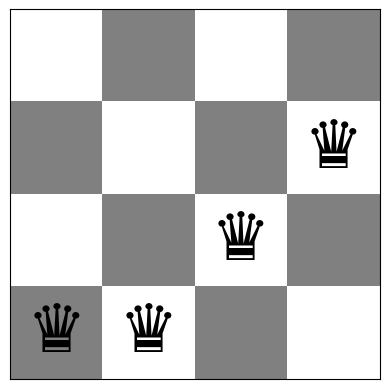

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [338]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


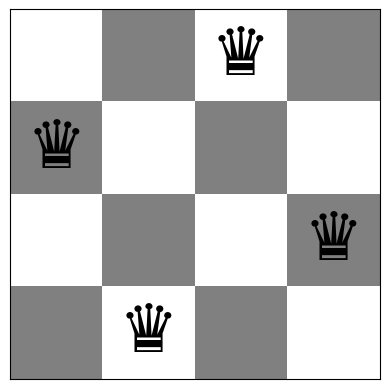

In [339]:
board = [1,3,0,2]
show_board(board)

### Phân tích bàn cờ mẫu `[1, 3, 0, 2]`

Bàn cờ 4 × 4 với quân hậu ở các vị trí (cột, hàng): (0, 1), (1, 3), (2, 0), (3, 2). Tất cả quân hậu đều không nằm trên cùng hàng, cột hay đường chéo nào, nên không có xung đột, không ăn nhau. Bài toán 4 hậu chỉ có 2 lời giải: `[1, 3, 0, 2]` và bản đối xứng của nó `[2, 0, 3, 1]`.

### __Hàm mục tiêu `h(board)` tìm số cặp quân cùng hàng và cùng đường chéo.__

In [340]:
def h(board): 
    n = len(board)
    count = 0
    for i in range(n-1):
        for j in range (i+1, n):
            same_row = board[i] == board[j]
            same_diag = abs(board[i] - board[j]) == abs(i-j)
            if same_row or same_diag:
                count += 1
    return count

In [341]:
#test the h function
print(f"Số lượng cặp quân hậu xung đột nhau: ")
print(h([1, 3, 0, 2]))
print(h([0, 0, 1, 1])) 

Số lượng cặp quân hậu xung đột nhau: 
0
3


Board with 4 conflicts.


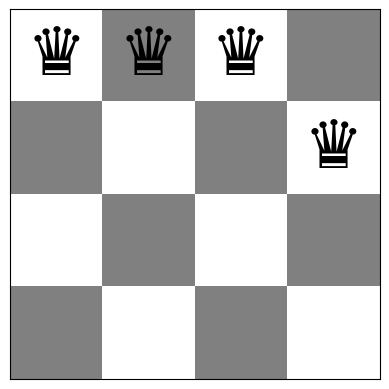

Số lượng cặp quân hậu xung đột nhau: 4


Board with 5 conflicts.


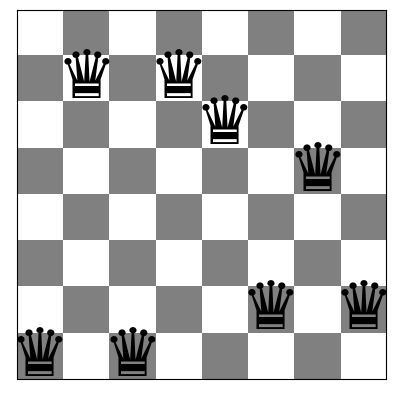

Số lượng cặp quân hậu xung đột nhau: 5


In [342]:
#Tạo bàn cờ n = 4 ngẫu nhiên và hiển thị số lượng cặp quân hậu xung đột nhau
board_4 = random_board(4)
show_board(board_4)
print(f"Số lượng cặp quân hậu xung đột nhau: {h(board_4)}")
print("\n")
board_8 = random_board(8)
show_board(board_8)
print(f"Số lượng cặp quân hậu xung đột nhau: {h(board_8)}")

Board with 0 conflicts.


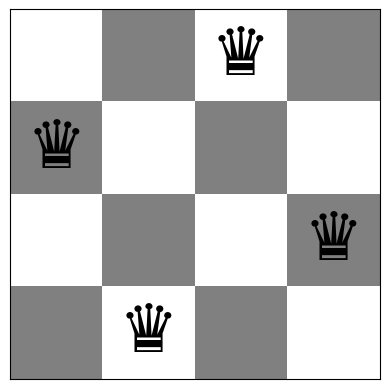

Số lượng cặp quân hậu xung đột nhau: 0


Board with 0 conflicts.


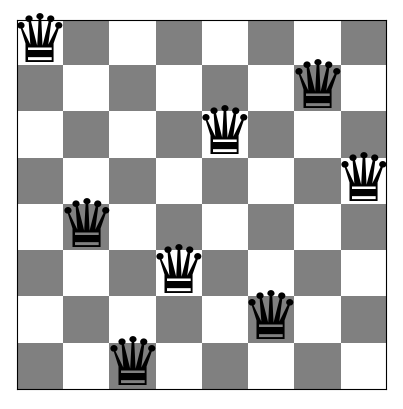

Số lượng cặp quân hậu xung đột nhau: 0


In [343]:
board_4 = [1, 3, 0, 2]
show_board(board_4)
print(f"Số lượng cặp quân hậu xung đột nhau: {h(board_4)}")
print("\n")
board_8 = [0, 4, 7, 5, 2, 6, 1, 3]
show_board(board_8)
print(f"Số lượng cặp quân hậu xung đột nhau: {h(board_8)}")

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points] (Tìm kiếm leo đồi theo hướng dốc nhất )

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 
- Tính giá trị hàm mục tiêu cho tất cả các bước di chuyển cục bộ (xem định nghĩa về các bước di chuyển cục bộ ở trên) và luôn chọn bước di chuyển tốt nhất trong số đó. Nếu không có bước di chuyển cục bộ nào giúp cải thiện hàm mục tiêu, thì bạn đã đạt đến một cực trị cục bộ (local optimum).


__Steepest-ascent Hill Climbing__ (leo đồi dốc nhất): ở mỗi bước, thuật toán thử **mọi** nước đi cục bộ (di chuyển một quân hậu sang hàng khác trong cùng cột), rồi chọn láng giềng có số xung đột **nhỏ nhất**. Bài toán là cực tiểu hóa số xung đột, nên "leo đồi" ở đây thực chất là đi xuống.

**Điều kiện dừng:**
- **h = 0:** tìm được lời giải tối ưu.
- **Láng giềng tốt nhất không tốt hơn trạng thái hiện tại** (best_h ≥ h): đã đến cực trị cục bộ, dừng dù h có thể vẫn > 0.

**Cài đặt và lựa chọn thiết kế:**
- `get_neighbors(board)`: sinh đủ $n(n-1)$ láng giềng (56 với $n = 8$). Dùng `board.copy()` để không làm thay đổi bàn cờ gốc.
- `best_neighbor(board)`: tính `conflicts` cho mọi láng giềng và trả về láng giềng tốt nhất. Khi có nhiều láng giềng cùng tốt nhất thì **chọn ngẫu nhiên**, tránh thiên lệch về các cột đầu.
- `steepest_ascent_hc(board)`: vòng lặp chính, chỉ chấp nhận nước đi **cải thiện thật sự** (`<`, không dùng `<=`), nên không đi ngang trên vùng bằng phẳng và không bị lặp vô hạn.
- Hàm trả về 6 giá trị: bàn cờ cuối, số xung đột cuối, số bước, lịch sử số xung đột (`history`), các bàn cờ qua từng bước (`path`) và **số lần đánh giá hàm mục tiêu** (`evals`).
- Dùng `conflicts()` ($O(n)$) thay cho `h()` ($O(n^2)$) vì cho cùng kết quả nhưng nhanh hơn.

**Số lần đánh giá hàm mục tiêu:** 1 lần cho bàn cờ ban đầu, cộng $n(n-1)$ lần cho mỗi lần gọi `best_neighbor` (kể cả lần cuối cùng phát hiện không còn nước cải thiện).

**Độ phức tạp mỗi bước:** $n(n-1)$ láng giềng × $O(n)$ cho mỗi lần tính xung đột = $O(n^3)$.

**Hình minh họa:** ở mỗi bước, mỗi ô trống ghi số xung đột nếu đưa quân hậu của cột đó sang ô này. Ô xanh lá là các láng giềng tốt nhất, ô viền đỏ là nước đi được chọn.

In [344]:
def get_neighbors(board):
    """Sinh mọi láng giềng: di chuyển 1 quân hậu sang hàng khác trong cùng cột.
    Mỗi bàn cờ n x n có n*(n-1) láng giềng."""
    n = len(board)
    neighbors = []
    for col in range(n):                 # chọn cột (quân hậu) cần di chuyển
        for row in range(n):             # chọn hàng mới
            if row != board[col]:        # bỏ qua vị trí hiện tại
                new_board = board.copy() # copy để không sửa bàn cờ gốc
                new_board[col] = row
                neighbors.append(new_board)
    return neighbors


def best_neighbor(board):
    """Tính số xung đột của mọi láng giềng và trả về láng giềng tốt nhất.
    Nếu nhiều láng giềng cùng tốt nhất thì chọn ngẫu nhiên một cái."""
    neighbors = get_neighbors(board)
    scores = [conflicts(nb) for nb in neighbors]
    best_h = min(scores)
    best_list = [nb for nb, s in zip(neighbors, scores) if s == best_h]
    best = best_list[np.random.randint(len(best_list))]
    return best, best_h


In [345]:
def steepest_ascent_hc(board, verbose=False, show_neighbors=False):
    """Steepest-ascent Hill Climbing.
    verbose=True: in ra từng bước.
    show_neighbors=True: vẽ số xung đột của mọi láng giềng ở mỗi bước và nước đi được chọn.
    Trả về: (bàn cờ cuối, số xung đột cuối, số bước, lịch sử số xung đột,
             danh sách bàn cờ qua từng bước, số lần đánh giá hàm mục tiêu)."""
    board = np.array(board).copy()
    n = len(board)
    h = conflicts(board)
    evals = 1                                        # đếm số lần tính hàm mục tiêu
    history = [h]
    path = [board.copy()]
    steps = 0
    while True:
        if h == 0:                                   # dừng 1: tìm được lời giải tối ưu
            if verbose:
                print("Xung đột = 0. Hoàn tất!")
            break
        nb, nb_h = best_neighbor(board)
        evals += n * (n - 1)                         # best_neighbor đánh giá toàn bộ n(n-1) láng giềng
        if nb_h >= h:                                # dừng 2: kẹt ở cực trị cục bộ
            if verbose:
                print(f"best_neighbor = {nb_h} conflicts, > {h}: "
                      f"=>dừng tại cực trị cục bộ.")
            if show_neighbors:
                show_neighbor_scores(board, title=f"Bước {steps + 1}: không còn neighbor tốt hơn")
            break
        col = int(np.where(nb != board)[0][0])       # cột có quân hậu được di chuyển
        if verbose:
            n_best = int((neighbor_scores(board) == nb_h).sum()) if show_neighbors else None
            msg = (f"Bước {steps + 1}: xét {len(board) * (len(board) - 1)} láng giềng, "
                               f"quân ở cột {col}: hàng {board[col]} -> {nb[col]} ,conflicts {h} -> {nb_h})")
            if n_best is not None and n_best > 1:
                msg += f", chọn ngẫu nhiên trong {n_best} láng giềng tốt nhất"
            print(msg)
        if show_neighbors:
            show_neighbor_scores(board, chosen=(col, nb[col]),
                                 title=f"Bước {steps + 1}: cột {col}, hàng {board[col]} -> {nb[col]}")
        board, h = nb, nb_h                          # di chuyển sang láng giềng tốt nhất
        steps += 1
        history.append(h)
        path.append(board.copy())
    return board, h, steps, history, path, evals


In [346]:
#bổ sung thêm bước hiển thị từng bước di chuyển của quân hậu
def show_steps(path, cols_per_row=4, fontsize=None):
    """Vẽ bàn cờ qua từng bước di chuyển.
    Quân hậu vừa di chuyển được tô đỏ, vị trí cũ đánh dấu bằng chấm đỏ."""
    n = len(path[0])
    k = len(path)
    nrows = int(np.ceil(k / cols_per_row))
    ncols = min(k, cols_per_row)
    if fontsize is None:
        fontsize = 120 // n               # tự giảm cỡ quân hậu khi bàn cờ lớn
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 4.0 * nrows),
                             squeeze=False)

    # bàn cờ trắng/xám
    display = np.array([[(i + j) % 2 for j in range(n)] for i in range(n)])
    cmap = colors.ListedColormap(['white', 'gray'])

    for idx, ax in enumerate(axes.flat):
        if idx >= k:                      # ô thừa trong lưới thì ẩn đi
            ax.axis('off')
            continue
        board = path[idx]
        ax.imshow(display, cmap=cmap)
        ax.set_xticks([]); ax.set_yticks([])

        # tìm cột có quân hậu vừa di chuyển (so với bước trước)
        moved = None
        if idx > 0:
            diff = np.where(path[idx] != path[idx - 1])[0]
            moved = diff[0] if len(diff) > 0 else None
            if moved is not None:         # chấm đỏ ở vị trí cũ
                ax.plot(moved, path[idx - 1][moved], 'o', color='red',
                        markersize=fontsize / 4)

        for j in range(n):
            ax.text(j, board[j], u"\u265B", fontsize=fontsize,
                    color='red' if j == moved else 'black',
                    ha='center', va='center')

        title = "Ban đầu" if idx == 0 else f"Bước {idx}"
        if moved is not None:
            title += f": cột {moved}, hàng {path[idx-1][moved]} -> {board[moved]}"
        ax.set_title(f"{title}\nconflicts = {conflicts(board)}", fontsize=8)

    plt.tight_layout()
    plt.show()

In [347]:
from matplotlib.patches import Rectangle

def neighbor_scores(board):
    """Ma trận n x n: ô (hàng r, cột c) = số xung đột nếu đưa quân hậu ở cột c sang hàng r.
    Ô đang có quân hậu được đặt là -1 (không phải láng giềng)."""
    n = len(board)
    scores = np.full((n, n), -1)
    for col in range(n):
        for row in range(n):
            if row != board[col]:
                nb = board.copy()
                nb[col] = row
                scores[row, col] = conflicts(nb)
    return scores


def show_neighbor_scores(board, chosen=None, title=None, fontsize=None):
    """Vẽ bàn cờ, ghi số xung đột của từng láng giềng vào ô tương ứng.
    Ô xanh lá: các láng giềng tốt nhất. Viền đỏ: nước đi được chọn."""
    n = len(board)
    if fontsize is None:
        fontsize = 140 // n
    scores = neighbor_scores(board)
    best_h = scores[scores >= 0].min()

    fig, ax = plt.subplots(figsize=(0.65 * n + 1.5, 0.65 * n + 1.5))
    display = np.array([[(i + j) % 2 for j in range(n)] for i in range(n)])
    ax.imshow(display, cmap=colors.ListedColormap(['white', 'lightgray']))
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xlabel('cột'); ax.set_ylabel('hàng')

    for col in range(n):
        for row in range(n):
            if row == board[col]:                       # vị trí quân hậu hiện tại
                ax.text(col, row, u"\u265B", fontsize=fontsize,
                        ha='center', va='center')
            else:
                s = scores[row, col]
                if s == best_h:                          # tô xanh láng giềng tốt nhất
                    ax.add_patch(Rectangle((col - .5, row - .5), 1, 1,
                                           color='lightgreen', alpha=.8))
                ax.text(col, row, str(s), fontsize=fontsize * 0.45,
                        ha='center', va='center')

    if chosen is not None:                               # viền đỏ ô được chọn
        c, r = chosen
        ax.add_patch(Rectangle((c - .5, r - .5), 1, 1, fill=False,
                               edgecolor='red', linewidth=3))

    head = title if title else ''
    ax.set_title(f"{head}\ncurrent = {conflicts(board)} conflicts, "
                 f"best_neighbors = {best_h}", fontsize=8)
    plt.tight_layout()
    plt.show()

4-Queens
Board with 5 conflicts.


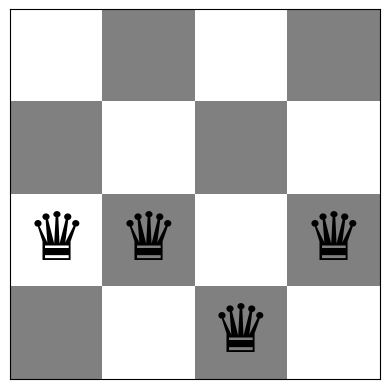

Bước 1: xét 12 láng giềng, quân ở cột 3: hàng 2 -> 1 ,conflicts 5 -> 2)


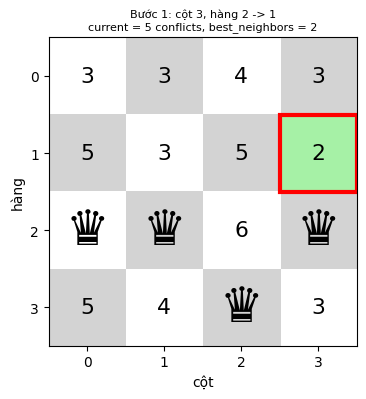

Bước 2: xét 12 láng giềng, quân ở cột 1: hàng 2 -> 0 ,conflicts 2 -> 0)


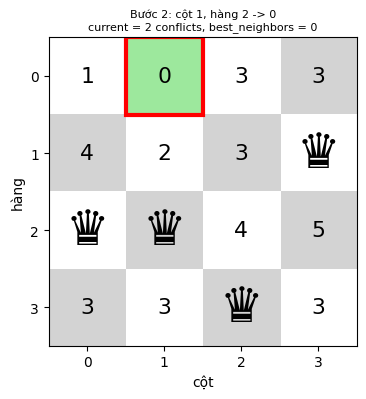

Xung đột = 0. Hoàn tất!
Kết thúc sau 2 bước, 0 xung đột


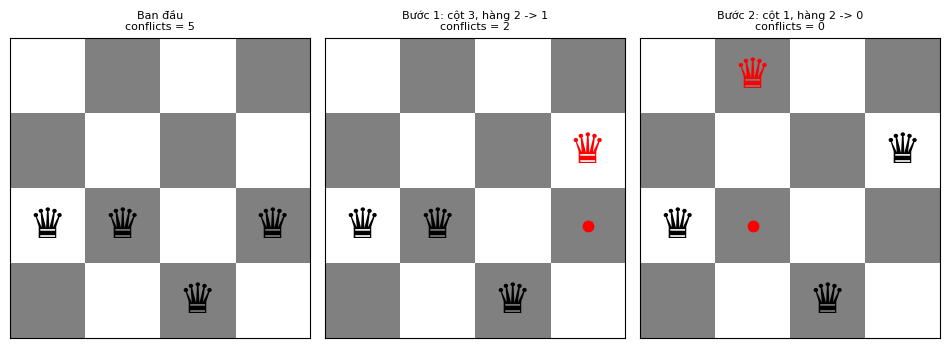

8-Queens
Board with 8 conflicts.


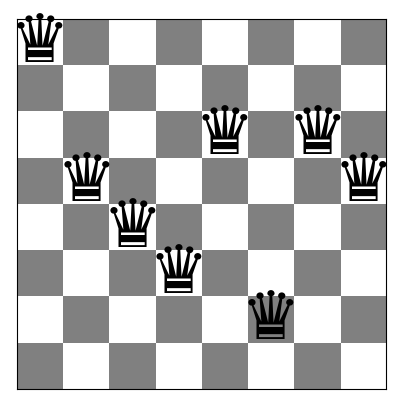

Bước 1: xét 56 láng giềng, quân ở cột 6: hàng 2 -> 1 ,conflicts 8 -> 5), chọn ngẫu nhiên trong 3 láng giềng tốt nhất


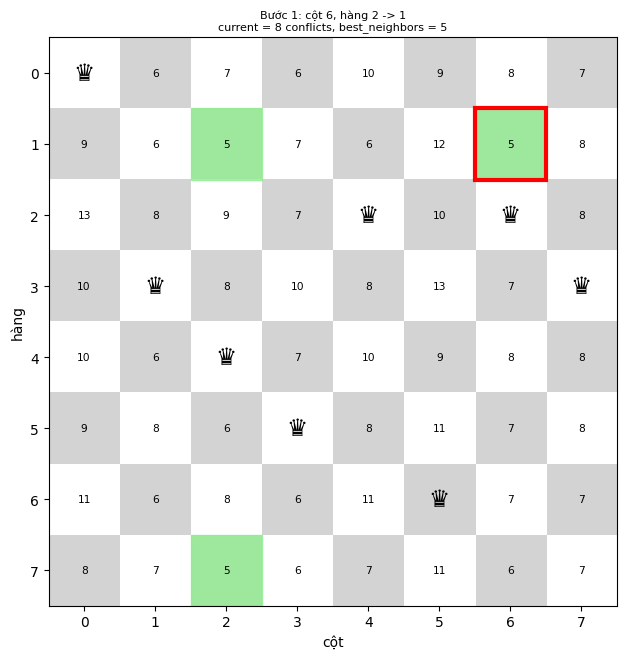

Bước 2: xét 56 láng giềng, quân ở cột 2: hàng 4 -> 7 ,conflicts 5 -> 2)


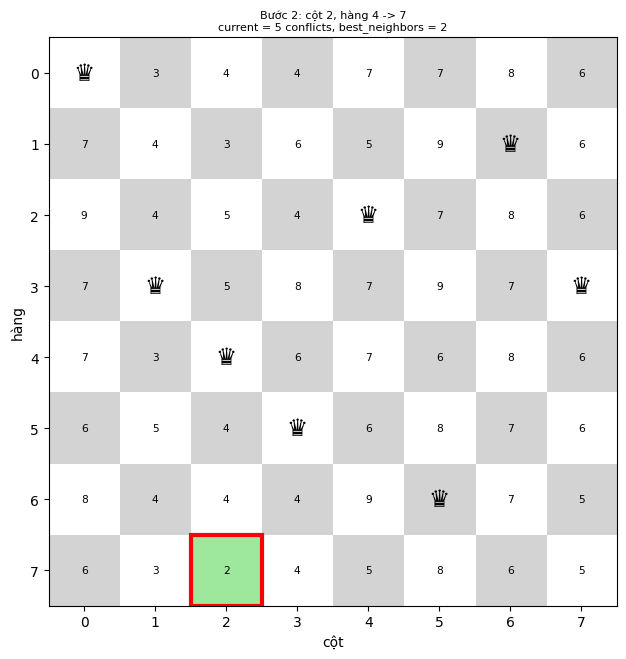

Bước 3: xét 56 láng giềng, quân ở cột 1: hàng 3 -> 4 ,conflicts 2 -> 0)


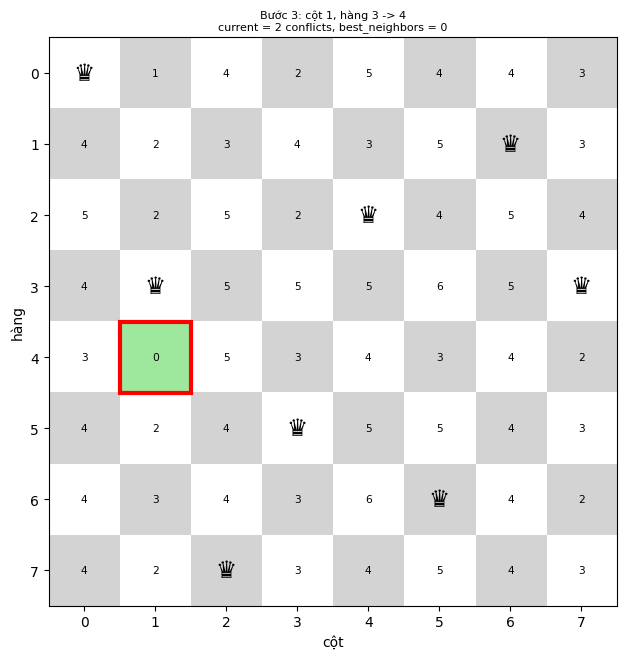

Xung đột = 0. Hoàn tất!
Kết thúc sau 3 bước, 0 xung đột


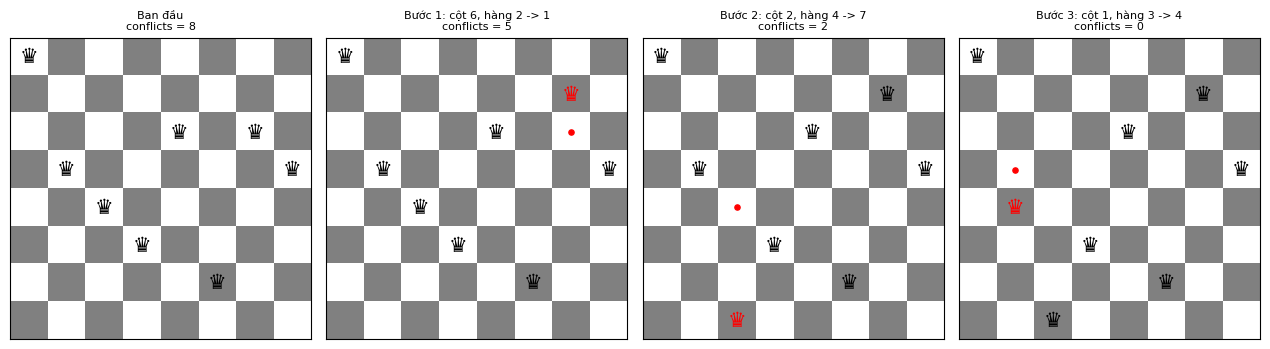

8-Queens: trường hợp bị kẹt ở cực trị cục bộ
Bước 1: xét 56 láng giềng, quân ở cột 5: hàng 6 -> 7 ,conflicts 8 -> 5)


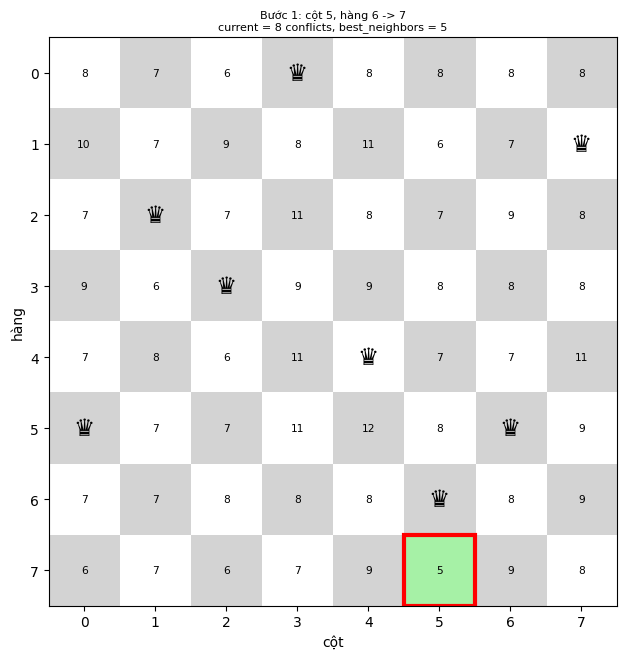

Bước 2: xét 56 láng giềng, quân ở cột 0: hàng 5 -> 6 ,conflicts 5 -> 3)


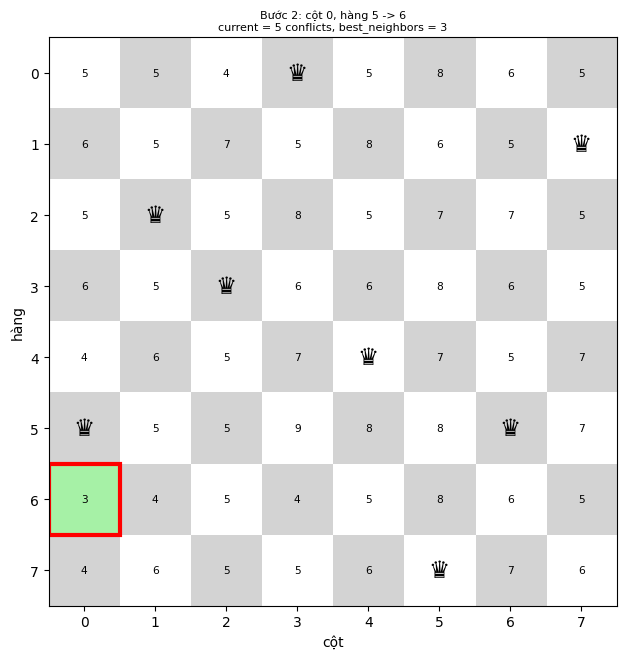

Bước 3: xét 56 láng giềng, quân ở cột 1: hàng 2 -> 6 ,conflicts 3 -> 2)


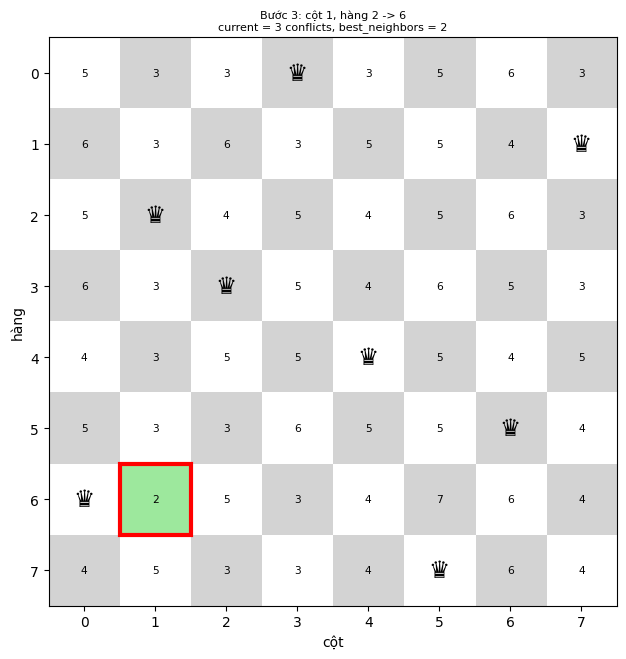

Bước 4: xét 56 láng giềng, quân ở cột 7: hàng 1 -> 2 ,conflicts 2 -> 1)


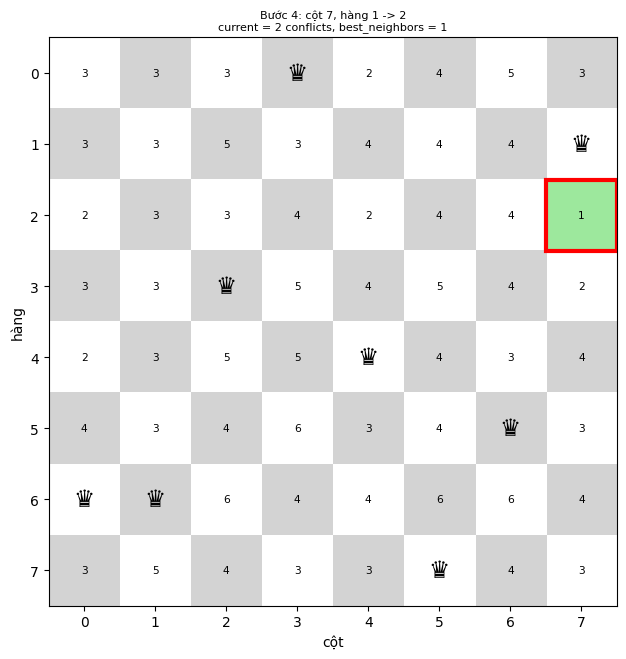

best_neighbor = 1 conflicts, > 1: =>dừng tại cực trị cục bộ.


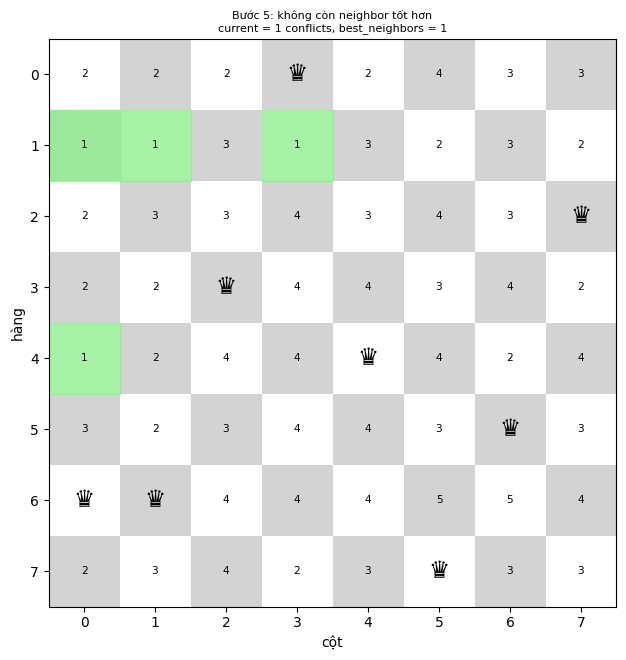

Kết thúc sau 4 bước, số xung đột = 1, số lần đánh giá = 281


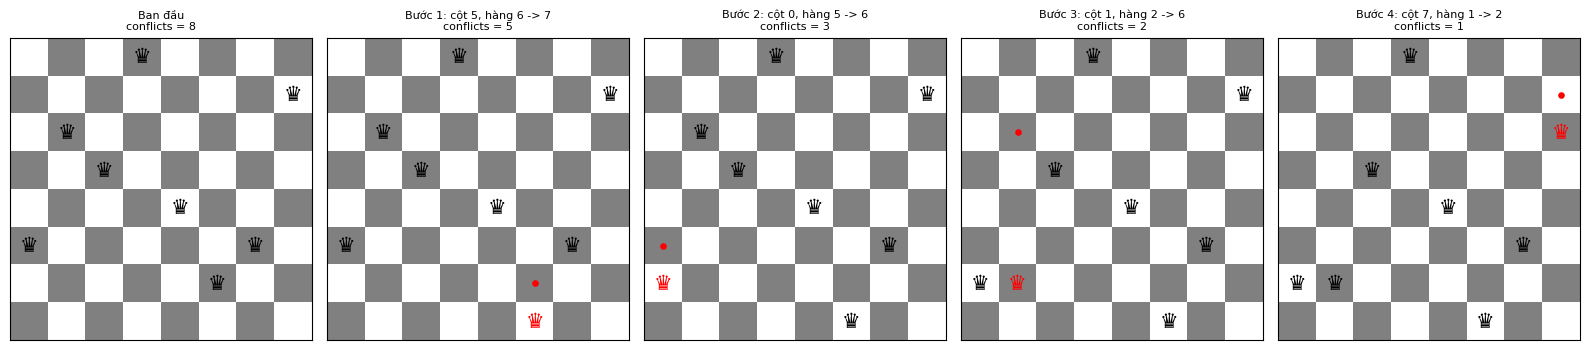

In [348]:
b_4 = [2, 2, 3, 2]
b_8 = [0, 3, 4, 5, 2, 6, 2, 3]
b_stuck = [5, 2, 3, 0, 4, 6, 5, 1] 

np.random.seed(1234)

print("4-Queens")
show_board(b_4)
final_board, final_h, steps, history, path, evals = steepest_ascent_hc(b_4, verbose=True, show_neighbors=True)
print(f"Kết thúc sau {steps} bước, {final_h} xung đột")
show_steps(path)

print("8-Queens")
show_board(b_8)
final_board, final_h, steps, history, path, evals = steepest_ascent_hc(b_8, verbose=True, show_neighbors=True)
print(f"Kết thúc sau {steps} bước, {final_h} xung đột")
show_steps(path)

print("8-Queens: trường hợp bị kẹt ở cực trị cục bộ")
final_board, final_h, steps, history, path, evals = steepest_ascent_hc(b_stuck, verbose=True, show_neighbors=True)
print(f"Kết thúc sau {steps} bước, số xung đột = {final_h}, số lần đánh giá = {evals}")
show_steps(path, cols_per_row=5)


## Task 2: Inefficient Stochastic Hill Climbing [10 Points] (Thuật toán leo đồi ngẫu nhiên kém hiệu quả)

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.
- Hãy sửa đổi thuật toán leo đồi theo hướng dốc nhất (steepest-ascent hill climbing) bằng cách chọn ngẫu nhiên một trong số các bước di chuyển hướng lên, cho đến khi đạt tới một cực trị địa phương (local optimum).

__Inefficient Stochastic Hill Climbing__ chỉ khác Task 1 ở cách chọn nước đi: thay vì chọn láng giềng **tốt nhất**, thuật toán chọn **ngẫu nhiên đều một trong các láng giềng có cải thiện** (số xung đột < hiện tại).

**Điều kiện dừng:** giống Task 1.
- **h = 0:** tìm được lời giải tối ưu.
- **Không còn láng giềng nào có ít xung đột hơn:** đã đến cực trị cục bộ.

**Cài đặt:**
- `random_improving_neighbor(board)`: dùng lại `get_neighbors` của Task 1, tính `conflicts` cho mọi láng giềng, lọc ra các láng giềng cải thiện rồi chọn ngẫu nhiên một cái. Trả về `None` nếu không có láng giềng nào cải thiện.
- `stochastic_hc(board)`: vòng lặp chính, cùng định dạng trả về 6 giá trị như `steepest_ascent_hc` để dùng chung cho Task 4 và Task 6.
- Chọn ngẫu nhiên **đều** (mỗi nước cải thiện có xác suất như nhau), đúng với yêu cầu "choosing randomly" của đề.

**Số lần đánh giá hàm mục tiêu:** mỗi bước cần $1 + n(n-1)$ lần (1 lần cho trạng thái hiện tại, $n(n-1)$ lần cho các láng giềng).

**Vì sao "kém hiệu quả":** thuật toán vẫn phải đánh giá **toàn bộ** láng giềng giống Task 1 ($O(n^3)$ mỗi bước), nhưng mỗi bước thường cải thiện ít hơn, nên cần **nhiều bước hơn** và tổng số lần đánh giá lớn hơn. Đổi lại, nó đi theo nhiều đường khác nhau nên đôi khi tránh được cực trị cục bộ mà Task 1 rơi vào.

In [349]:
def random_improving_neighbor(board):
    """Inefficient Stochastic HC: tính số xung đột của MỌI láng giềng,
    lọc ra các láng giềng có cải thiện (xung đột < hiện tại),
    rồi chọn ngẫu nhiên (đều) một láng giềng trong số đó.
    Trả về (None, h) nếu không có láng giềng nào cải thiện."""
    h = conflicts(board)
    improving = []                                   # danh sách (láng giềng, số xung đột)
    for nb in get_neighbors(board):
        nb_h = conflicts(nb)
        if nb_h < h:                                 # chỉ giữ nước đi cải thiện thật sự
            improving.append((nb, nb_h))
    if len(improving) == 0:                          # không còn nước cải thiện
        return None, h
    idx = np.random.randint(len(improving))          # chọn ngẫu nhiên một nước cải thiện
    return improving[idx]

In [350]:
def stochastic_hc(board, verbose=False):
    """Inefficient Stochastic Hill Climbing.
    Trả về: (bàn cờ cuối, số xung đột cuối, số bước, lịch sử số xung đột,
             danh sách bàn cờ qua từng bước, số lần đánh giá hàm mục tiêu)."""
    board = np.array(board).copy()
    n = len(board)
    h = conflicts(board)
    evals = 1                                        # đếm số lần tính hàm mục tiêu
    history = [h]
    path = [board.copy()]
    steps = 0
    while True:
        if h == 0:                                   # dừng 1: tìm được lời giải tối ưu
            if verbose:
                print("Conflicts = 0. Hoàn tất!")
            break
        nb, nb_h = random_improving_neighbor(board)
        evals += 1 + n * (n - 1)                     # 1 lần cho trạng thái hiện tại + n(n-1) láng giềng
        if nb is None:                               # dừng 2: kẹt ở cực trị cục bộ
            if verbose:
                print(f"Không còn neighbors < {h} xung đột: dừng tại cực trị cục bộ.")
            break
        if verbose:
            col = int(np.where(nb != board)[0][0])   # cột có quân hậu được di chuyển
            print(f"Bước {steps + 1}: cột {col}, hàng {board[col]} -> {nb[col]} "
                  f"(conflicts = {h} -> {nb_h})", )
        board, h = nb, nb_h                          # di chuyển sang láng giềng được chọn
        steps += 1
        history.append(h)
        path.append(board.copy())
    return board, h, steps, history, path, evals

=== 4-Queens ===
Bước 1: cột 2, hàng 3 -> 0 (conflicts = 5 -> 4)
Bước 2: cột 3, hàng 2 -> 1 (conflicts = 4 -> 3)
Bước 3: cột 0, hàng 2 -> 0 (conflicts = 3 -> 2)
Bước 4: cột 2, hàng 0 -> 3 (conflicts = 2 -> 1)
Không còn neighbors < 1 xung đột: dừng tại cực trị cục bộ.
Kết thúc sau 4 bước, số xung đột = 1, số lần đánh giá = 66


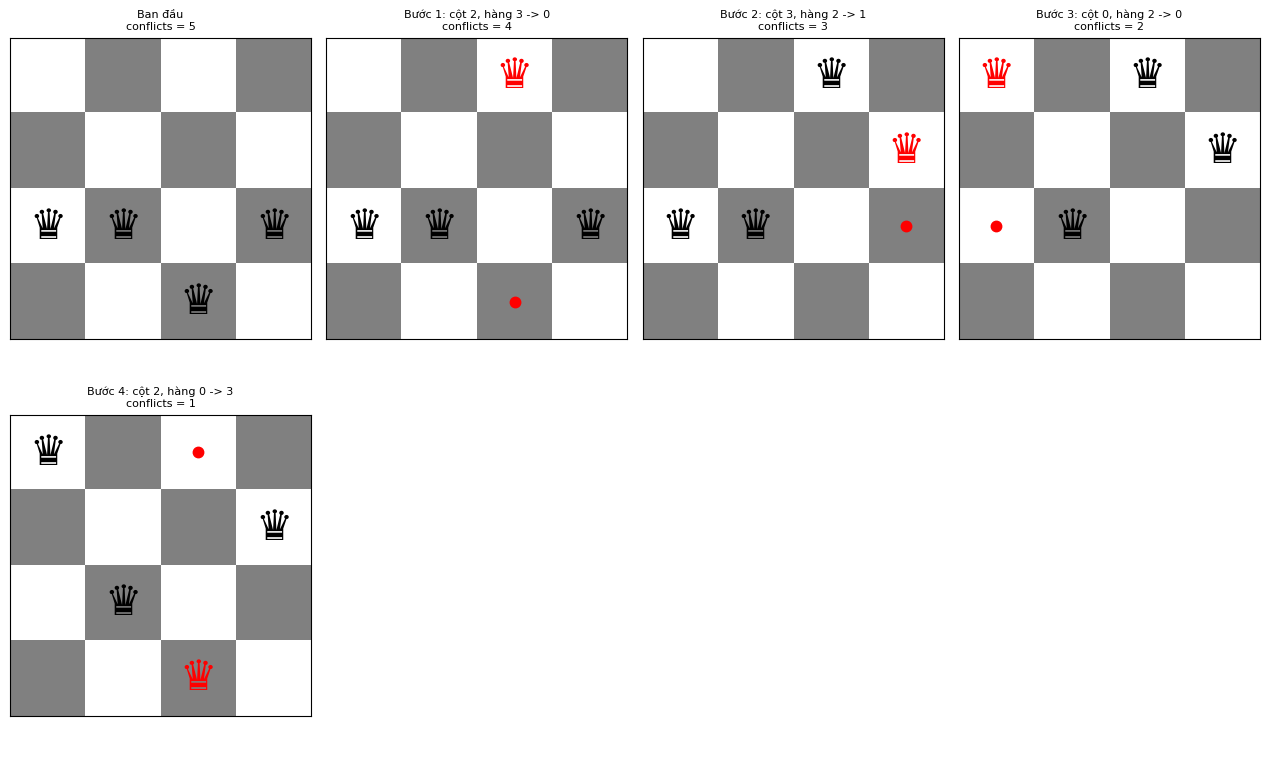

=== 8-Queens ===
Bước 1: cột 4, hàng 2 -> 1 (conflicts = 8 -> 6)
Bước 2: cột 6, hàng 2 -> 1 (conflicts = 6 -> 5)
Bước 3: cột 2, hàng 4 -> 7 (conflicts = 5 -> 3)
Bước 4: cột 1, hàng 3 -> 2 (conflicts = 3 -> 2)
Không còn neighbors < 2 xung đột: dừng tại cực trị cục bộ.
Kết thúc sau 4 bước, số xung đột = 2, số lần đánh giá = 286


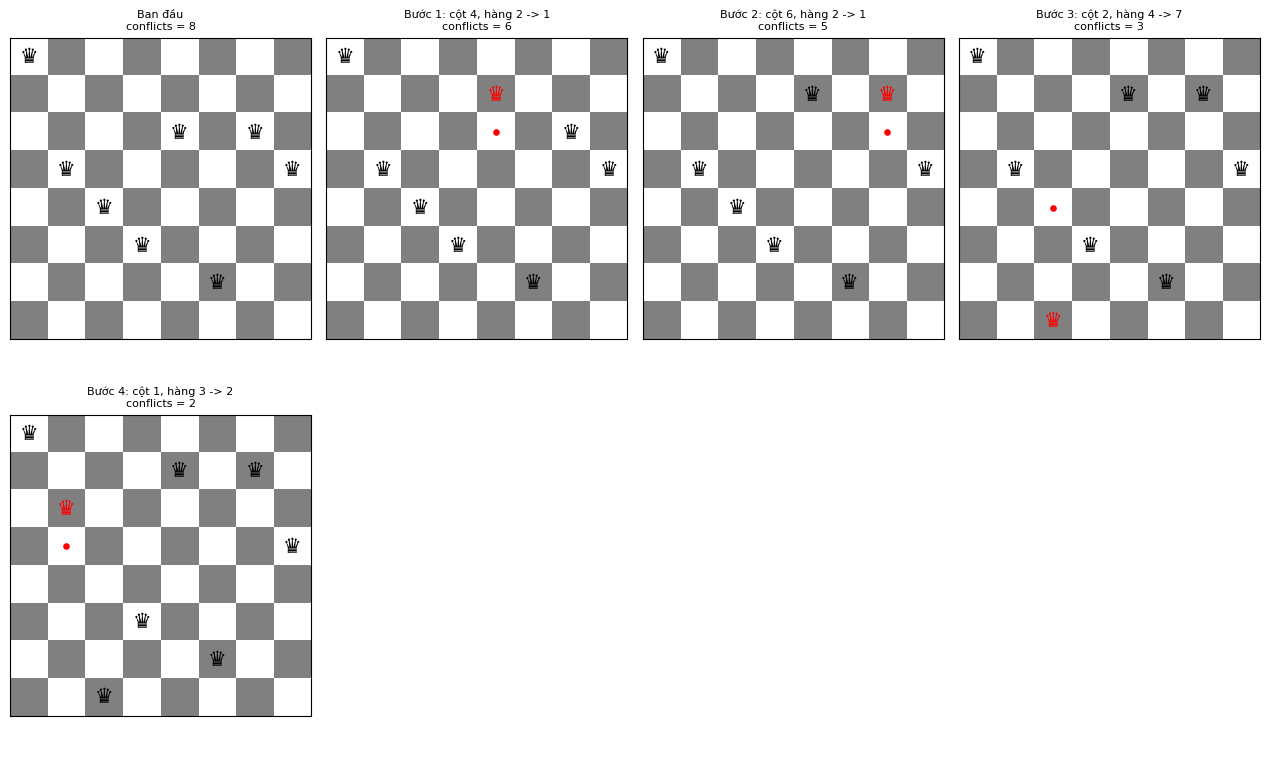

In [351]:


print("=== 4-Queens ===")
final_board, final_h, steps, history, path, evals = stochastic_hc(b_4, verbose=True)
print(f"Kết thúc sau {steps} bước, số xung đột = {final_h}, số lần đánh giá = {evals}")
show_steps(path)

print("=== 8-Queens ===")
final_board, final_h, steps, history, path, evals = stochastic_hc(b_8, verbose=True)
print(f"Kết thúc sau {steps} bước, số xung đột = {final_h}, số lần đánh giá = {evals}")
show_steps(path)

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points] (Thuật toán leo đồi ngẫu nhiên hiệu quả )

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time. (Tại mỗi thời điểm, chỉ tạo ra một trạng thái lân cận ngẫu nhiên duy nhất.)
2. Accept the move if it has a better objective function value than the current state. (Chấp nhận bước di chuyển nếu trạng thái mới có giá trị hàm mục tiêu tốt hơn trạng thái hiện tại.)
3. Repeat till a stopping criterion is met. (Lặp lại cho đến khi đạt đến tiêu chí dừng.)

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."
Trong thực tế, thuật toán leo đồi ngẫu nhiên (stochastic hill climbing) luôn được triển khai theo cách sau:
- Phương pháp này đặc biệt hiệu quả trong trường hợp mỗi trạng thái có rất nhiều trạng thái kế tiếp khả dĩ. Trong giáo trình, phương pháp này được gọi là "leo đồi chọn lựa đầu tiên" (first-choice hill climbing), còn trong thực tế, nó thường được gọi đơn giản là "leo đồi ngẫu nhiên".





__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.
- Việc phát hiện các cực trị địa phương (local optima) khá phức tạp vì bạn không tính toán giá trị hàm mục tiêu cho tất cả các bước di chuyển lân cận! Một cách tiếp cận phổ biến là dừng thuật toán nếu không tìm thấy cải thiện nào cho hàm mục tiêu sau $x$ lần thử liên tiếp. Bạn cần lập luận để xác định giá trị $x$ phù hợp; giá trị này sẽ phụ thuộc vào kích thước của bàn cờ. Gợi ý: Bạn đang lấy mẫu ngẫu nhiên các bước di chuyển lân cận từ tập hợp tất cả các bước di chuyển khả dĩ (có hoàn lại), và mục tiêu là đảm bảo rằng bạn đã thử qua hầu hết các khả năng trước khi quyết định dừng lại.

__Efficient Stochastic Hill Climbing__ (First-choice Hill Climbing): mỗi lần chỉ sinh **một** láng giềng ngẫu nhiên và tính số xung đột của nó. Nếu láng giềng tốt hơn trạng thái hiện tại thì chấp nhận ngay, nếu không thì thử láng giềng ngẫu nhiên khác.

**Cài đặt:**
- `random_neighbor(board)`: chọn ngẫu nhiên một cột và một hàng mới **khác** hàng hiện tại, nên mỗi lần thử luôn là một nước đi hợp lệ trong $m = n(n-1)$ nước đi.
- `efficient_stochastic_hc(board)`: chỉ chấp nhận nước đi có số xung đột **nhỏ hơn** (`<`). Biến `fails` đếm số lần thử thất bại **liên tiếp** và được đặt lại về 0 mỗi khi có cải thiện.
- Mỗi lần thử chỉ tốn **1 lần** đánh giá hàm mục tiêu ($O(n)$), thay vì $n(n-1)$ lần như Task 1 và Task 2.

**Điều kiện dừng** (để tránh lặp vô hạn):
1. **h = 0:** tìm được lời giải tối ưu.
2. **`fails` ≥ x:** x lần thử liên tiếp không cải thiện, coi như đã ở cực trị cục bộ.
3. **Số lần lặp vượt `max_iters`** (100.000): giới hạn an toàn, đảm bảo vòng lặp luôn kết thúc.

**Chọn x:** có $m = n(n-1)$ nước đi, mỗi lần thử lấy mẫu **có hoàn lại**. Trường hợp xấu nhất là chỉ còn **một** nước cải thiện. Xác suất không lấy được nước đó sau x lần thử là $(1 - 1/m)^x$. Ta chọn x nhỏ nhất sao cho xác suất này ≤ 1%:

$$
x = \left\lceil \frac{\ln 0.01}{\ln(1 - 1/m)} \right\rceil \approx 4.6\, m
$$

- $n = 4$: $m = 12$, $x = 53$
- $n = 8$: $m = 56$, $x = 256$

Như vậy x tăng theo $n^2$. Giá trị này cũng gần với bài toán "thu thập phiếu" ($m \ln m \approx 225$ với $n = 8$): trung bình cần ngần ấy lần thử để đã gặp hầu hết các nước đi.

khi đang cải thiện, thuật toán rất rẻ (thường chỉ vài lần thử mỗi bước). Nhưng để **xác nhận** đã kẹt, nó phải thử x ≈ 4.6m lần, nhiều hơn một lần quét toàn bộ m láng giềng của Task 1. Vì vậy với bàn cờ nhỏ, tổng số lần đánh giá chưa chắc ít hơn Task 1. Lợi thế thể hiện rõ khi n lớn, vì mỗi bước của Task 1 tốn $O(n^3)$.

In [352]:
import math

def max_fails(n, p=0.01):
    """Số lần thử thất bại liên tiếp x trước khi dừng.
    Có m = n(n-1) nước đi, lấy mẫu có hoàn lại. Chọn x nhỏ nhất sao cho xác suất
    bỏ sót một nước đi cụ thể sau x lần thử là ≤ p: (1 - 1/m)^x ≤ p."""
    m = n * (n - 1)
    return math.ceil(math.log(p) / math.log(1 - 1 / m))


def random_neighbor(board):
    """Sinh MỘT láng giềng ngẫu nhiên: chọn ngẫu nhiên 1 cột và 1 hàng mới khác hàng hiện tại."""
    n = len(board)
    col = np.random.randint(n)
    row = np.random.randint(n - 1)                   # chọn trong n-1 hàng còn lại
    if row >= board[col]:                            # bỏ qua hàng hiện tại
        row += 1
    nb = board.copy()
    nb[col] = row
    return nb


def efficient_stochastic_hc(board, max_fails_x=None, max_iters=100_000, verbose=False):
    """Efficient Stochastic (First-choice) Hill Climbing.
    Dừng khi: h = 0, hoặc x lần thử liên tiếp không cải thiện, hoặc vượt max_iters.
    Trả về: (bàn cờ cuối, số xung đột cuối, số bước, lịch sử số xung đột,
             danh sách bàn cờ qua từng bước, số lần đánh giá hàm mục tiêu)."""
    board = np.array(board).copy()
    n = len(board)
    x = max_fails(n) if max_fails_x is None else max_fails_x
    h = conflicts(board)
    evals = 1
    history = [h]
    path = [board.copy()]
    steps = 0
    fails = 0                                        # số lần thử thất bại liên tiếp
    for _ in range(max_iters):                       # giới hạn an toàn, tránh lặp vô hạn
        if h == 0:                                   # dừng 1: tìm được lời giải tối ưu
            if verbose:
                print("Đã đạt 0 xung đột: tìm được lời giải.")
            break
        if fails >= x:                               # dừng 2: x lần liên tiếp không cải thiện
            if verbose:
                print(f"{x} lần thử liên tiếp không cải thiện: dừng (nhiều khả năng là cực trị cục bộ).")
            break
        nb = random_neighbor(board)
        nb_h = conflicts(nb)
        evals += 1                                   # mỗi lần thử chỉ tốn 1 lần đánh giá
        if nb_h < h:                                 # chỉ chấp nhận nước đi tốt hơn
            if verbose:
                col = int(np.where(nb != board)[0][0])
                print(f"Bước {steps + 1} (sau {fails + 1} lần thử): cột {col}, "f"hàng {board[col]} -> {nb[col]} (conflicts {h} -> {nb_h})")
            board, h = nb, nb_h
            steps += 1
            fails = 0                                # có cải thiện thì đặt lại bộ đếm
            history.append(h)
            path.append(board.copy())
        else:
            fails += 1
    return board, h, steps, history, path, evals

x cho n = 4: 53, x cho n = 8: 256
=== 4-Queens ===
Bước 1 (sau 1 lần thử): cột 3, hàng 2 -> 3 (conflicts 5 -> 3)
Bước 2 (sau 1 lần thử): cột 1, hàng 2 -> 0 (conflicts 3 -> 1)
Bước 3 (sau 3 lần thử): cột 3, hàng 3 -> 1 (conflicts 1 -> 0)
Đã đạt 0 xung đột: tìm được lời giải.
Kết thúc sau 3 bước, số xung đột = 0, số lần đánh giá = 6


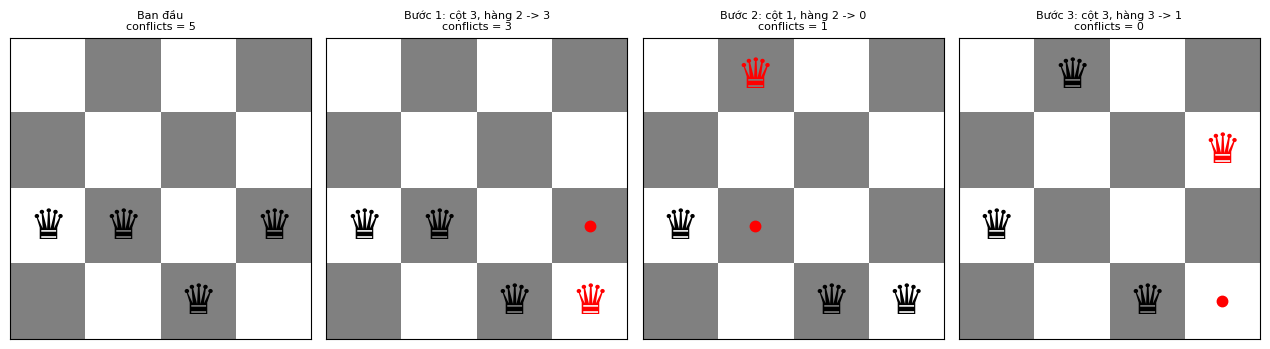

=== 8-Queens ===
Bước 1 (sau 1 lần thử): cột 2, hàng 4 -> 7 (conflicts 8 -> 5)
Bước 2 (sau 13 lần thử): cột 7, hàng 3 -> 4 (conflicts 5 -> 4)
Bước 3 (sau 53 lần thử): cột 3, hàng 5 -> 7 (conflicts 4 -> 3)
Bước 4 (sau 10 lần thử): cột 6, hàng 2 -> 1 (conflicts 3 -> 2)
256 lần thử liên tiếp không cải thiện: dừng (nhiều khả năng là cực trị cục bộ).
Kết thúc sau 4 bước, số xung đột = 2, số lần đánh giá = 334


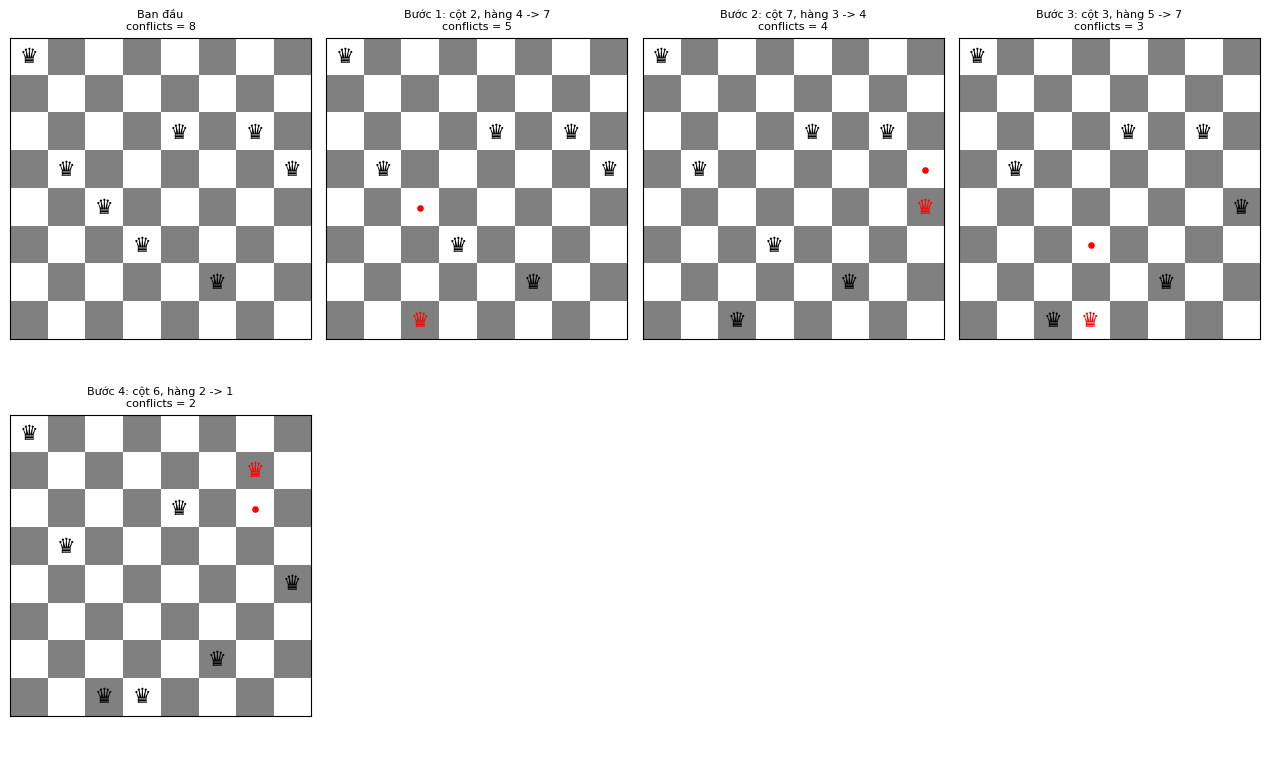

In [353]:
print(f"x cho n = 4: {max_fails(4)}, x cho n = 8: {max_fails(8)}")
np.random.seed(1234)

print("=== 4-Queens ===")
final_board, final_h, steps, history, path, evals = efficient_stochastic_hc(b_4, verbose=True)
print(f"Kết thúc sau {steps} bước, số xung đột = {final_h}, số lần đánh giá = {evals}")
show_steps(path)

print("=== 8-Queens ===")
final_board, final_h, steps, history, path, evals = efficient_stochastic_hc(b_8, verbose=True)
print(f"Kết thúc sau {steps} bước, số xung đột = {final_h}, số lần đánh giá = {evals}")
show_steps(path)

### Ghi nhận kết quả của Task 1 đến Task 3

Với mỗi lần chạy, ta ghi nhận: số xung đột cuối, số bước (số nước đi được chấp nhận), số lần đánh giá hàm mục tiêu và **trạng thái kết thúc**. Hàm `classify_end` kiểm tra toàn bộ láng giềng của bàn cờ cuối (chỉ để phân loại, không tính vào số lần đánh giá):
- **Tối ưu:** h = 0.
- **Cực tiểu cục bộ:** mọi láng giềng đều có **nhiều** xung đột hơn.
- **Plateau:** không có láng giềng tốt hơn, nhưng có láng giềng **bằng** h. Vì cả 3 thuật toán không cho phép đi ngang (chỉ nhận `<`), chúng dừng tại đây.
- **Dừng sớm:** vẫn còn nước cải thiện nhưng thuật toán đã dừng. Chỉ có thể xảy ra ở Task 3, khi x lần thử ngẫu nhiên đều bỏ sót nước cải thiện.

In [363]:
import time

def classify_end(board):
    """Phân loại trạng thái kết thúc bằng cách xét toàn bộ láng giềng của bàn cờ cuối."""
    h = conflicts(board)
    if h == 0:
        return "Tối ưu"
    best = min(conflicts(nb) for nb in get_neighbors(board))
    if best < h:
        return "Dừng sớm"
    if best == h:
        return "Plateau"
    return "Cực tiểu cục bộ"


ALGOS = {
    "Steepest-ascent HC": steepest_ascent_hc,
    "Ineff. Stochastic HC": stochastic_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc,
}



def run_once_table(boards):
    """Chạy 3 thuật toán trên cùng các bàn cờ cho trước và in bảng kết quả."""
    print(f"{'Thuật toán':<25}{'n':>3}  {'Bàn cờ':<28}{'h cuối':>7}"
          f"{'Số bước':>9}{'Số lần đánh giá':>17}  Kết thúc")
    for name, alg in ALGOS.items():
        for b in boards:
            np.random.seed(1234)
            fb, fh, st, hist, path, ev = alg(b)
            print(f"{name:<25}{len(b):>3}  {str(list(b)):<28}{fh:>7}{st:>9}{ev:>17}  {classify_end(fb)}")
        print("\n")


def run_many(n, runs=100, seed=42):
    """Chạy 3 thuật toán trên cùng `runs` bàn cờ ngẫu nhiên và in giá trị trung bình."""
    np.random.seed(seed)
    starts = [random_board(n) for _ in range(runs)]
    print(f"\nn = {n}, {runs} bàn cờ ngẫu nhiên (cùng bộ bàn cờ cho cả 3 thuật toán)")
    print(f"{'Thuật toán':<25}{'TB h cuối':>10}{'TB số bước':>12}{'TB số đánh giá':>16}"
          f"{'% Tối ưu':>10}{'% Cực tiểu':>12}{'% Plateau':>11}{'TB thời gian (ms)':>19}")
    for name, alg in ALGOS.items():
        t0 = time.perf_counter()
        res = [alg(b) for b in starts]
        t = (time.perf_counter() - t0) / runs * 1000
        ends = [classify_end(r[0]) for r in res]
        print(f"{name:<25}{np.mean([r[1] for r in res]):>10.2f}{np.mean([r[2] for r in res]):>12.1f}"
              f"{np.mean([r[5] for r in res]):>16.1f}{100 * ends.count('Tối ưu') / runs:>10.0f}"
              f"{100 * ends.count('Cực tiểu cục bộ') / runs:>12.0f}"
              f"{100 * ends.count('Plateau') / runs:>11.0f}{t:>19.2f}")


run_once_table([b_4, b_8, b_stuck])


Thuật toán                 n  Bàn cờ                       h cuối  Số bước  Số lần đánh giá  Kết thúc
Steepest-ascent HC         4  [2, 2, 3, 2]                      0        2               25  Tối ưu
Steepest-ascent HC         8  [0, 3, 4, 5, 2, 6, 2, 3]          0        3              169  Tối ưu
Steepest-ascent HC         8  [5, 2, 3, 0, 4, 6, 5, 1]          1        4              281  Plateau


Ineff. Stochastic HC       4  [2, 2, 3, 2]                      1        3               53  Plateau
Ineff. Stochastic HC       8  [0, 3, 4, 5, 2, 6, 2, 3]          1        4              286  Plateau
Ineff. Stochastic HC       8  [5, 2, 3, 0, 4, 6, 5, 1]          1        6              400  Plateau


Efficient Stochastic HC    4  [2, 2, 3, 2]                      0        3                6  Tối ưu
Efficient Stochastic HC    8  [0, 3, 4, 5, 2, 6, 2, 3]          0        4               84  Tối ưu
Efficient Stochastic HC    8  [5, 2, 3, 0, 4, 6, 5, 1]          0        5               2

In [355]:
run_many(4)
run_many(8)


n = 4, 100 bàn cờ ngẫu nhiên (cùng bộ bàn cờ cho cả 3 thuật toán)
Thuật toán                TB h cuối  TB số bước  TB số đánh giá  % Tối ưu  % Cực tiểu  % Plateau  TB thời gian (ms)
Steepest-ascent HC             0.66         1.6            27.3        39           0         61               0.28
Ineff. Stochastic HC           0.74         2.0            34.8        36           0         64               0.29
Efficient Stochastic HC        0.79         1.9            49.1        31           0         68               0.71

n = 8, 100 bàn cờ ngẫu nhiên (cùng bộ bàn cờ cho cả 3 thuật toán)
Thuật toán                TB h cuối  TB số bước  TB số đánh giá  % Tối ưu  % Cực tiểu  % Plateau  TB thời gian (ms)
Steepest-ascent HC             1.16         3.3           231.7        17           0         83               2.66
Ineff. Stochastic HC           1.24         4.9           327.6        19           1         80               3.50
Efficient Stochastic HC        1.34         4.9       

### Nhận xét

- **Tỷ lệ tìm được lời giải thấp:** với n = 8, cả 3 thuật toán chỉ tìm được lời giải trong khoảng 11–19% số lần chạy. Phần lớn các lần chạy dừng khi h vẫn > 0, thường là h = 1 hoặc 2.
- **Phần lớn trường hợp mắc kẹt là plateau, không phải cực tiểu cục bộ chặt:** khi dừng, gần như luôn có láng giềng **bằng** số xung đột hiện tại. Vì cả 3 thuật toán chỉ nhận nước đi tốt hơn hẳn (`<`), chúng không đi ngang được để thoát khỏi vùng bằng phẳng này. Đây là hạn chế mà Task 4 (khởi động lại ngẫu nhiên) và Task 5 (simulated annealing) sẽ khắc phục.
- **Số bước:** Steepest-ascent cần ít bước nhất vì mỗi bước chọn nước giảm nhiều nhất. Task 2 và Task 3 chọn bất kỳ nước cải thiện nào nên mỗi bước giảm ít hơn và cần nhiều bước hơn.
- **Số lần đánh giá:** Task 2 tốn nhiều nhất vì vừa quét toàn bộ láng giềng, vừa cần nhiều bước. Task 3 rất rẻ khi đang cải thiện, nhưng phải thử x = 256 lần để xác nhận đã kẹt, nên với n = 8 tổng số lần đánh giá chưa thấp hơn Task 1. Lợi thế của Task 3 sẽ rõ hơn khi n lớn (phân tích ở Task 6).
- **Cùng một bàn cờ có thể cho kết quả khác nhau:** bàn cờ `[5, 2, 3, 0, 4, 6, 5, 1]` luôn làm Task 1 kẹt ở h = 1, nhưng Task 3 lại tìm được lời giải. Tính ngẫu nhiên giúp đi theo đường khác, đôi khi tránh được bẫy mà thuật toán tham lam rơi vào.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Steepest-ascent HC: thành công=1, số lần khởi tạo=5, restart=4, bước=17, đánh giá=1181, thời gian=0.01839s
Board with 0 conflicts.


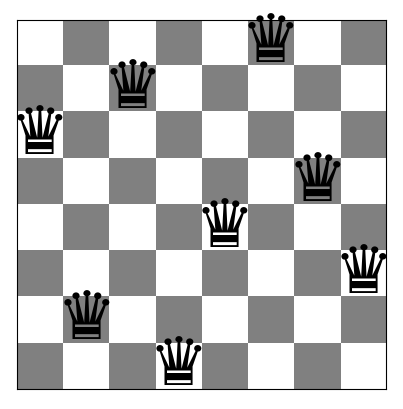

Inefficient Stochastic HC: thành công=1, số lần khởi tạo=4, restart=3, bước=18, đánh giá=1201, thời gian=0.01738s
Board with 0 conflicts.


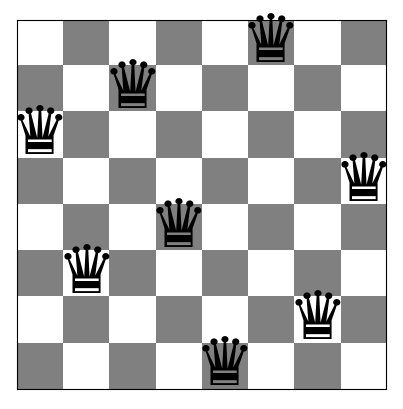

Efficient Stochastic HC: thành công=1, số lần khởi tạo=15, restart=14, bước=62, đánh giá=4379, thời gian=0.12184s
Board with 0 conflicts.


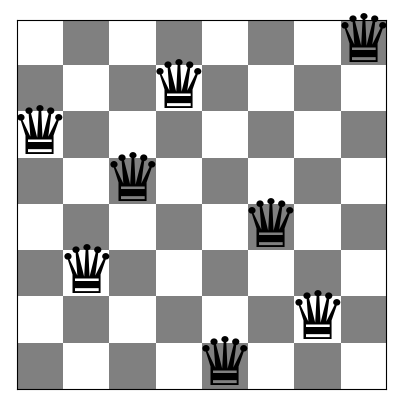

,Algorithm,Successful runs,Total runs,Success rate (%),Avg. starts,Avg. steps,Avg. evals,Avg. runtime (s)
0,Steepest-ascent HC,100,100,100.0,8.12,25.53,1836.52,0.02775
1,Inefficient Stochastic HC,100,100,100.0,8.20,40.43,2723.11,0.03968
2,Efficient Stochastic HC,100,100,100.0,5.94,29.19,1662.53,0.04423


In [ ]:
import time
import pandas as pd

def random_restart_hc(algorithm, n=8, max_starts=100):
    """Một CHUỖI Random Restart: tối đa max_starts bàn cờ, dừng ngay khi h=0."""
    best_board, best_h = None, float("inf")
    total_steps, total_evals = 0, 0
    start = time.perf_counter()
    for attempt in range(1, max_starts + 1):
        board = random_board(n)
        final_board, final_h, steps, history, path, evals = algorithm(board)
        total_steps += steps
        total_evals += evals
        if final_h < best_h:
            best_board, best_h = final_board.copy(), final_h
        if final_h == 0:
            break
    return {"success": int(best_h == 0), "starts": attempt,
            "restarts": attempt - 1, "best_h": best_h,
            "steps": total_steps, "evals": total_evals,
            "runtime_s": time.perf_counter() - start,
            "best_board": best_board}

restart_algos = {
    "Steepest-ascent HC": steepest_ascent_hc,
    "Inefficient Stochastic HC": stochastic_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc,
}
np.random.seed(1234)
for name, fn in restart_algos.items():
    r = random_restart_hc(fn, n=8, max_starts=100)
    print(f"{name}: thành công={r['success']}, "
          f"số lần khởi tạo={r['starts']}, restart={r['restarts']}, "
          f"bước={r['steps']}, "
          f"đánh giá={r['evals']}, thời gian={r['runtime_s']:.5f}s")
    show_board(r["best_board"])

n_experiments = 100
restart_rows = []
for idx, (name, fn) in enumerate(restart_algos.items()):
    np.random.seed(8765 + idx)
    runs = [random_restart_hc(fn, n=8, max_starts=100)
            for _ in range(n_experiments)]
    restart_rows.append({
        "Algorithm": name,
        "Successful runs": sum(r["success"] for r in runs),
        "Total runs": n_experiments,
        "Success rate (%)": 100 * np.mean([r["success"] for r in runs]),
        "Avg. starts": np.mean([r["starts"] for r in runs]),
        "Avg. steps": np.mean([r["steps"] for r in runs]),
        "Avg. evals": np.mean([r["evals"] for r in runs]),
        "Avg. runtime (s)": np.mean([r["runtime_s"] for r in runs]),
    })
restart_df = pd.DataFrame(restart_rows)
display(restart_df.round(5))

### Nhận xét:

Qua 100 lượt thử nghiệm với bài toán 8 quân hậu, cả ba thuật toán Hill Climbing 
kết hợp Random Restart đều đạt tỷ lệ thành công 100%, cho thấy khả năng tìm nghiệm 
hiệu quả khi được khởi động lại từ nhiều trạng thái ngẫu nhiên.

Xét về chi phí tính toán, **Steepest-ascent HC có số bước và thời gian thực thi trung bình thấp nhất**, 
lần lượt là 25,53 bước và 0,01771 giây. Trong khi đó, **Efficient Stochastic HC có số lần đánh giá hàm 
mục tiêu trung bình thấp nhất** với 1.662,53 lần. Inefficient Stochastic HC có chi phí cao nhất theo cả ba chỉ số.

Nhìn chung, Random Restart giúp các biến thể Hill Climbing tăng khả năng tìm được nghiệm bằng cách 
khởi động lại khi mắc kẹt tại cực trị cục bộ. Tuy nhiên, hiệu quả tính toán khác nhau 
tùy thuộc vào chiến lược lựa chọn láng giềng của từng thuật toán.

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

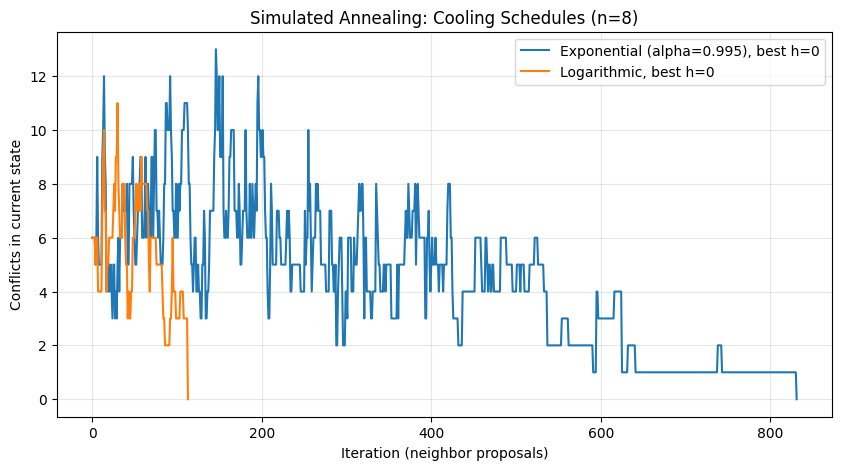

,Schedule,best h,steps,evals,runtime (s)
0,Exponential (alpha=0.995),0,427,832,0.03489
1,Logarithmic,0,83,114,0.00279


Bàn cờ khởi đầu: [5 2 0 2 4 2 3 1] h = 6


In [ ]:
import math
import time
import pandas as pd

def simulated_annealing(board, T0=10.0, alpha=0.995, Tmin=0.001,
                        max_iters=10000, schedule="exponential"):
    current = np.asarray(board, dtype=int).copy()
    current_h = conflicts(current)
    best_board = current.copy()
    best_h = current_h
    history = [current_h]  
    path = [current.copy()]
    evals, steps = 1, 0
    for t in range(max_iters):
        if current_h == 0:
            break
        if schedule == "exponential":
            T = T0 * (alpha ** t)
        elif schedule == "logarithmic":
            T = T0 / math.log(t + 2)
        else:
            raise ValueError("schedule must be 'exponential' or 'logarithmic'")
        if T < Tmin:
            break
        nb = random_neighbor(current)
        nb_h = conflicts(nb)
        evals += 1
        delta = nb_h - current_h
        if delta <= 0 or np.random.random() < math.exp(-delta / T):
            current, current_h = nb, nb_h
            steps += 1
            path.append(current.copy())
            if current_h < best_h:
                best_board, best_h = current.copy(), current_h
        history.append(current_h)
    return best_board, best_h, steps, history, path, evals

np.random.seed(4321)
sa_start = random_board(8)
sa_schedules = [
    ("Exponential (alpha=0.995)", {"schedule": "exponential", "T0": 10, "alpha": 0.995}),
    ("Logarithmic", {"schedule": "logarithmic", "T0": 10}),
]
sa_rows = []
plt.figure(figsize=(10, 5))
for i, (label, kw) in enumerate(sa_schedules):
    np.random.seed(2026)  
    t0 = time.perf_counter()
    final_board, final_h, steps, history, path, evals = simulated_annealing(sa_start, **kw)
    duration = time.perf_counter() - t0
    sa_rows.append({"Schedule": label, "best h": final_h, "steps": steps,
                    "evals": evals, "runtime (s)": duration})
    plt.plot(history, label=f"{label}, best h={final_h}")
plt.xlabel("Iteration (neighbor proposals)")
plt.ylabel("Conflicts in current state")
plt.title("Simulated Annealing: Cooling Schedules (n=8)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
display(pd.DataFrame(sa_rows).round(5))
print("Bàn cờ khởi đầu:", sa_start, "h =", conflicts(sa_start))

### Nhận xét

Kết quả thực nghiệm cho thấy cả hai lịch làm nguội Exponential Cooling và Logarithmic Cooling đều tìm được nghiệm hợp lệ cho bài toán 8 quân hậu, với số xung đột tốt nhất bằng 0.

Xét về chi phí tính toán, Exponential Cooling cần 427 bước, 832 lần đánh giá hàm mục tiêu và 0,02024 giây. Trong khi đó, Logarithmic Cooling chỉ cần 83 bước, 114 lần đánh giá và 0,00167 giây. Như vậy, Logarithmic Cooling cho hiệu quả tốt hơn trong lần thử nghiệm này.

Biểu đồ hội tụ cho thấy số xung đột không giảm liên tục mà có những thời điểm tăng lên. Điều này phản ánh đặc trưng của Simulated Annealing: thuật toán có thể chấp nhận trạng thái xấu hơn theo một xác suất phụ thuộc vào nhiệt độ, từ đó tăng khả năng thoát khỏi cực trị cục bộ.

**Kết luận:** Cả hai lịch làm nguội đều giải quyết thành công bài toán 8 quân hậu. Trong lần thử nghiệm này, Logarithmic Cooling hội tụ nhanh hơn và có chi phí tính toán thấp hơn Exponential Cooling. Tuy nhiên, do thuật toán có tính ngẫu nhiên, cần thực hiện nhiều lượt chạy để đưa ra kết luận tổng quát về hiệu quả của từng lịch làm nguội.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

,Algorithm,Board size,Avg. Run time (s),Avg. number of conflicts,% of runs ending in optimal solution,Avg. steps,Avg. evals
0,Steepest asc. HC,4,0.00018,0.70,36.0,1.55,27.28
1,Ineff. Stochastic HC,4,0.00018,0.79,33.0,1.90,34.41
2,Efficient Stochastic HC,4,0.00041,0.82,30.0,1.88,49.67
3,Simulated Annealing,4,0.00134,0.00,100.0,104.99,116.28
4,Steepest asc. HC,8,0.00193,1.17,19.0,3.32,232.28
5,Ineff. Stochastic HC,8,0.00275,1.32,9.0,4.96,335.59
6,Efficient Stochastic HC,8,0.00337,1.30,16.0,5.07,280.01
7,Simulated Annealing,8,0.01452,0.14,86.0,447.94,1087.99


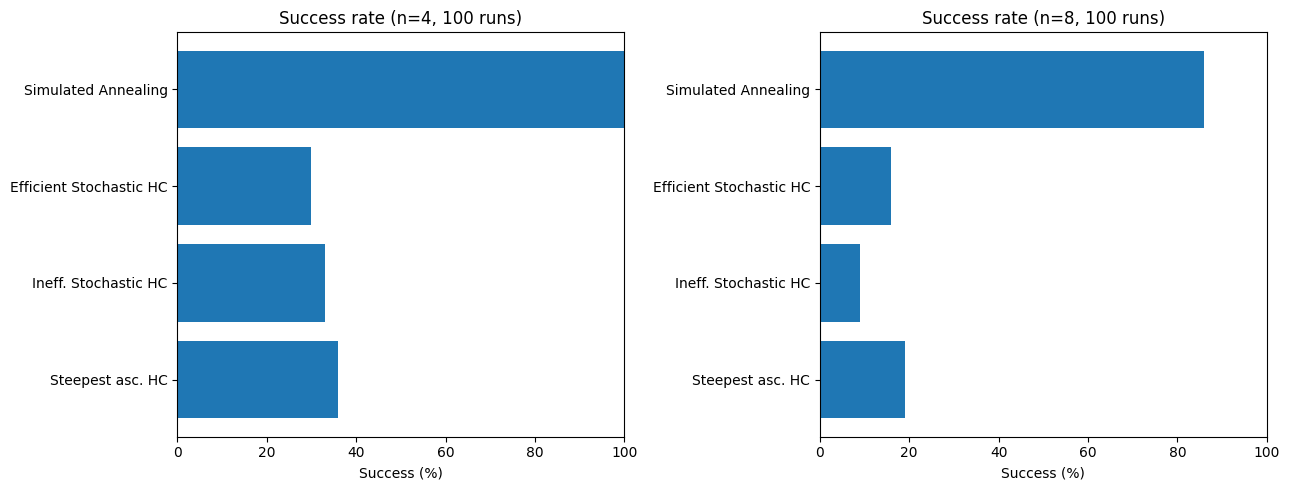

In [ ]:
import pandas as pd
import time

comparison_algos = {
    "Steepest asc. HC": steepest_ascent_hc,
    "Ineff. Stochastic HC": stochastic_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc,
    "Simulated Annealing": lambda b: simulated_annealing(b, T0=10, alpha=0.995),
}
comparison_rows = []
for n in (4, 8):
    np.random.seed(1000 + n)
    boards = [random_board(n) for _ in range(100)]
    for alg_idx, (name, fn) in enumerate(comparison_algos.items()):
        times, hs, steps_, evals_ = [], [], [], []
        for trial, board in enumerate(boards):
            np.random.seed(50000 + alg_idx * 1000 + trial)
            t0 = time.perf_counter()
            _, h_final, steps, history, path, evals = fn(board.copy())
            times.append(time.perf_counter() - t0)
            hs.append(h_final)
            steps_.append(steps)
            evals_.append(evals)
        comparison_rows.append({
            "Algorithm": name, "Board size": n,
            "Avg. Run time (s)": np.mean(times),
            "Avg. number of conflicts": np.mean(hs),
            "% of runs ending in optimal solution": 100 * np.mean(np.array(hs) == 0),
            "Avg. steps": np.mean(steps_),
            "Avg. evals": np.mean(evals_),
        })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(5))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, n in zip(axes, (4, 8)):
    sub = comparison_df[comparison_df["Board size"] == n]
    ax.barh(sub["Algorithm"], sub["% of runs ending in optimal solution"])
    ax.set_title(f"Success rate (n={n}, 100 runs)")
    ax.set_xlim(0, 100)
    ax.set_xlabel("Success (%)")
plt.tight_layout()
plt.show()

### Nhận xét:

Kết quả thực nghiệm qua 100 lượt chạy tại hai kích thước bàn cờ n = 4 và n = 8 cho thấy sự khác biệt rõ rệt về hiệu quả giữa các thuật toán Hill Climbing và Simulated Annealing.

**1. Về tỷ lệ tìm được nghiệm tối ưu**

Simulated Annealing đạt tỷ lệ thành công cao nhất ở cả hai kích thước bàn cờ, với 100% tại n = 4 và 86% tại n = 8. Trong khi đó, các biến thể Hill Climbing chỉ đạt từ 30–36% tại n = 4 và giảm xuống còn 9–19% tại n = 8.

Điều này cho thấy Simulated Annealing có khả năng thoát khỏi cực trị cục bộ tốt hơn nhờ cơ chế chấp nhận những trạng thái có số xung đột cao hơn theo xác suất.

**2. Về số xung đột trung bình**

Simulated Annealing có số xung đột trung bình thấp nhất, đạt 0 tại n = 4 và 0,14 tại n = 8. Ngược lại, các thuật toán Hill Climbing có số xung đột trung bình từ 0,70–0,82 tại n = 4 và 1,17–1,32 tại n = 8.

Kết quả cho thấy Simulated Annealing có khả năng tìm được trạng thái ít xung đột hơn so với các biến thể Hill Climbing trong thí nghiệm này.

**3. Về chi phí tính toán**

Các thuật toán Hill Climbing có thời gian thực thi và số lần đánh giá hàm mục tiêu thấp hơn đáng kể so với Simulated Annealing.

Tại n = 8, Steepest-ascent HC có thời gian chạy trung bình thấp nhất (0,00193 giây) và số lần đánh giá ít nhất (232,28 lần). Trong khi đó, Simulated Annealing cần 0,01452 giây và 1.087,99 lần đánh giá trung bình.

Điều này cho thấy Simulated Annealing phải đánh đổi chi phí tính toán lớn hơn để tăng khả năng tìm được nghiệm tối ưu.

**4. Ảnh hưởng của kích thước bàn cờ**

Khi kích thước tăng từ n = 4 lên n = 8, tỷ lệ thành công của cả bốn thuật toán đều giảm, đồng thời thời gian thực thi và số lần đánh giá hàm mục tiêu tăng lên.

Đặc biệt, tỷ lệ thành công của Inefficient Stochastic HC giảm từ 33% xuống còn 9%, trong khi Simulated Annealing vẫn duy trì tỷ lệ thành công tương đối cao ở mức 86%.

**Kết luận:** Simulated Annealing cho hiệu quả tìm nghiệm tốt nhất trong thí nghiệm, với tỷ lệ thành công cao và số xung đột trung bình thấp. Ngược lại, các biến thể Hill Climbing có ưu điểm về tốc độ và chi phí tính toán nhưng dễ mắc kẹt tại cực trị cục bộ. Vì vậy, lựa chọn thuật toán phụ thuộc vào việc ưu tiên chất lượng nghiệm hay chi phí thực thi.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

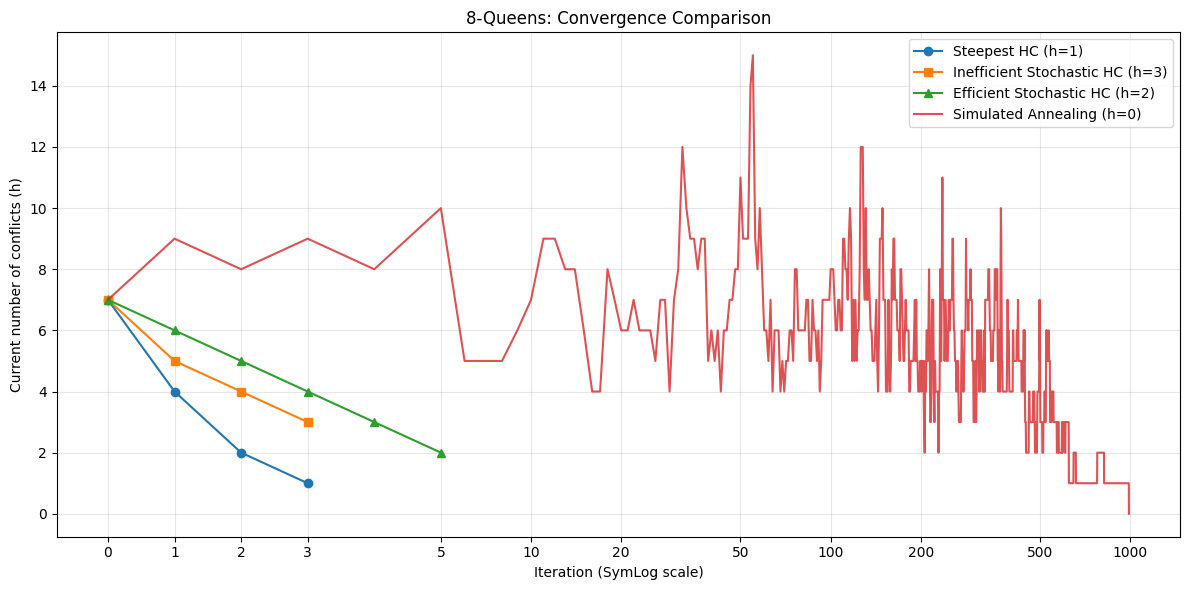

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

np.random.seed(2026)
board0 = random_board(8)

np.random.seed(300)
b1, h1, s1, hist1, path1, e1 = steepest_ascent_hc(board0.copy())

np.random.seed(301)
b2, h2, s2, hist2, path2, e2 = stochastic_hc(board0.copy())

np.random.seed(302)
b3, h3, s3, hist3, path3, e3 = efficient_stochastic_hc(board0.copy())

np.random.seed(303)
b4, h4, s4, hist4, path4, e4 = simulated_annealing(
    board0.copy(), T0=10, alpha=0.995
)

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(hist1)), hist1,
    marker='o',
    label=f"Steepest HC (h={h1})"
)

plt.plot(
    range(len(hist2)), hist2,
    marker='s',
    label=f"Inefficient Stochastic HC (h={h2})"
)

plt.plot(
    range(len(hist3)), hist3,
    marker='^',
    markevery=max(1, len(hist3)//15),
    label=f"Efficient Stochastic HC (h={h3})"
)

plt.plot(
    range(len(hist4)), hist4,
    linewidth=1.5,
    alpha=0.8,
    label=f"Simulated Annealing (h={h4})"
)

# Trục SymLog
plt.xscale("symlog", linthresh=5)

ticks = [0, 1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000]

plt.xticks(ticks)

plt.gca().xaxis.set_major_formatter(
    ticker.ScalarFormatter()
)

plt.xlabel("Iteration (SymLog scale)")
plt.ylabel("Current number of conflicts (h)")
plt.title("8-Queens: Convergence Comparison")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Chú thích:** Biểu đồ sử dụng thang SymLog nhằm thể hiện rõ quá trình hội tụ của các thuật toán có số bước tìm kiếm chênh lệch lớn. Do cách cài đặt khác nhau, các biến thể Hill Climbing chủ yếu ghi nhận những bước cải thiện, trong khi Simulated Annealing ghi nhận từng lần thử láng giềng. Vì vậy, biểu đồ được sử dụng để quan sát xu hướng thay đổi số xung đột và hiện tượng mắc kẹt, không dùng để so sánh trực tiếp chi phí theo số vòng lặp.

### Nhận xét

Biểu đồ thể hiện quá trình hội tụ của bốn thuật toán trên bài toán 8 quân hậu, với cùng trạng thái khởi tạo có 7 cặp quân hậu xung đột.

**Về tốc độ cải thiện:** Ba biến thể Hill Climbing đều giảm nhanh số xung đột trong những bước đầu. Steepest-ascent HC giảm từ h = 7 xuống h = 1 sau 3 bước cải thiện, Efficient Stochastic HC đạt h = 2 sau 5 bước, trong khi Inefficient Stochastic HC dừng tại h = 3 sau 3 bước. Điều này cho thấy các thuật toán Hill Climbing có khả năng cải thiện nhanh số xung đột trong giai đoạn đầu.

**Về hiện tượng local optimum và plateau:** Cả ba thuật toán Hill Climbing đều dừng khi chưa đạt nghiệm tối ưu (h = 0), cho thấy chúng không tìm được bước cải thiện tiếp theo theo chiến lược tìm kiếm đang sử dụng. Trong khi đó, Simulated Annealing có số xung đột dao động mạnh, có thời điểm tăng lên đến h = 15 do cơ chế chấp nhận trạng thái xấu hơn. Các đoạn nằm ngang thể hiện những giai đoạn số xung đột không thay đổi, nhưng thuật toán vẫn có thể tiếp tục khám phá không gian trạng thái.

**Về khả năng hội tụ:** Simulated Annealing cần nhiều lần thử láng giềng hơn, nhưng số xung đột nhìn chung có xu hướng giảm về cuối quá trình tìm kiếm và cuối cùng đạt h = 0 sau khoảng 1.000 lần thử, tìm được nghiệm tối ưu.

**Kết luận:** Hill Climbing cải thiện nhanh trong những bước đầu nhưng dễ dừng tại trạng thái chưa tối ưu. Ngược lại, Simulated Annealing có khả năng thoát khỏi cực trị cục bộ nhờ cơ chế chấp nhận các trạng thái xấu hơn, tuy nhiên cần nhiều lần thử láng giềng hơn trong lượt chạy này.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

**Thực nghiệm khả năng mở rộng (log-log)**
Đo thời gian một lần chạy với n = 4, 8, 12, 16, 20 cho ít nhất hai thuật toán. Mỗi kích thước dùng các bàn cờ khởi đầu giống nhau giữa các thuật toán và lặp nhiều lần để giảm dao động. Biểu đồ log-log sử dụng trung bình thời gian; đường xu hướng hồi quy chỉ cho số mũ thực nghiệm trên phạm vi n khảo sát, không phải chứng minh Big-O lý thuyết. Thời gian tùy thuộc phần cứng, ngẫu nhiên và cài đặt conflicts.

Ở mỗi kích thước bàn cờ $n \in {4,8,12,16,20}$, chạy thuật toán 20 lần và tính thời gian chạy trung bình $T(n)$. Khi $n$ tăng, ta muốn biết $T(n)$ tăng nhanh đến mức nào.

Ta giả sử để xấp xỉ dữ liệu rằng trong khoảng $n$ đang khảo sát, thời gian tuân theo dạng $T(n) \approx a n^p$. Ở đây, $a$ là hệ số tỷ lệ và $p$ là số mũ chưa biết, được tính từ thời gian đo, không phải số mũ có sẵn trong thuật toán. Ví dụ, nếu $n$ tăng gấp đôi: với $p=1$ thì thời gian tăng khoảng 2 lần; $p=2$ thì tăng khoảng 4 lần; $p=3$ thì tăng khoảng 8 lần.

In [ ]:
import numpy as np
import pandas as pd
import time

sizes = [4, 8, 12, 16, 20]
n_runs = 20

algorithms = {
    "Steepest-ascent HC": steepest_ascent_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc
}

results = []

for n in sizes:
    np.random.seed(700 + n)
    boards = [random_board(n) for _ in range(n_runs)]

    for name, algorithm in algorithms.items():
        runtimes = []
        evaluations = []
        conflicts_final = []

        for i, board in enumerate(boards):
            np.random.seed(10000 + i)

            start = time.perf_counter()
            final_board, h, steps, history, path, evals = algorithm(
                board.copy()
            )
            elapsed = time.perf_counter() - start

            runtimes.append(elapsed)
            evaluations.append(evals)
            conflicts_final.append(h)

        results.append({
            "Board size (n)": n,
            "Algorithm": name,
            "Avg. runtime (s)": np.mean(runtimes),
            "Avg. evals": np.mean(evaluations),
            "Avg. final h": np.mean(conflicts_final)
        })

scale_df = pd.DataFrame(results)
display(scale_df.round(6))

# Tính số mũ độ phức tạp thực nghiệm
exponents = {}

print("\nExperimental Complexity:")

for name in algorithms:
    data = scale_df[scale_df["Algorithm"] == name]

    x = data["Board size (n)"].to_numpy(dtype=float)
    y = data["Avg. runtime (s)"].to_numpy(dtype=float)

    p, log_a = np.polyfit(np.log(x), np.log(y), 1)
    exponents[name] = p

    print(f"{name}: T(n) ~ n^{p:.2f}")


,Board size (n),Algorithm,Avg. runtime (s),Avg. evals,Avg. final h
0,4,Steepest-ascent HC,0.000147,25.00,0.60
1,4,Efficient Stochastic HC,0.000433,45.35,0.75
2,8,Steepest-ascent HC,0.002210,258.60,1.30
3,8,Efficient Stochastic HC,0.003749,313.95,1.45
4,12,Steepest-ascent HC,0.008688,746.80,1.80
5,12,Efficient Stochastic HC,0.011902,769.20,1.65
6,16,Steepest-ascent HC,0.029352,1849.00,2.15
7,16,Efficient Stochastic HC,0.029023,1529.10,2.50
8,20,Steepest-ascent HC,0.062710,3478.00,2.60
9,20,Efficient Stochastic HC,0.051395,2304.15,2.65



Experimental Complexity:
Steepest-ascent HC: T(n) ~ n^3.76
Efficient Stochastic HC: T(n) ~ n^2.98



### Giải thích cách ước lượng độ phức tạp thực nghiệm

Để đánh giá mức độ gia tăng thời gian chạy khi kích thước bàn cờ thay đổi, ta giả sử thời gian thực thi tuân theo mô hình:

$$
T(n) \approx a \cdot n^p
$$

Trong đó:
- $T(n)$: Thời gian chạy của thuật toán.
- $n$: Kích thước bàn cờ.
- $a$: Hệ số tỷ lệ.
- $p$: Số mũ biểu thị tốc độ tăng trưởng thời gian.

**Ví dụ:** Xét thuật toán Steepest-ascent HC với kết quả thực nghiệm:

- Khi $n=4$, thời gian chạy là 0,000147 giây.
- Khi $n=8$, thời gian chạy là 0,002210 giây.

Kích thước bàn cờ tăng gấp 2 lần, trong khi thời gian chạy tăng khoảng 15,03 lần. Do đó:

$$
2^p \approx 15.03
$$

Suy ra:

$$
p \approx \frac{\ln(15.03)}{\ln(2)} \approx 3.91
$$

Giá trị này chỉ được tính từ hai điểm dữ liệu. Để ước lượng chính xác hơn, chương trình sử dụng cả năm kích thước $n \in \{4,8,12,16,20\}$.

Lấy logarithm hai vế của mô hình:

$$
\ln T(n) \approx \ln a + p\ln n
$$

Chương trình sử dụng `np.polyfit(np.log(x), np.log(y), 1)` để tìm đường thẳng phù hợp nhất với dữ liệu trên hệ trục log-log. Hệ số góc của đường thẳng chính là số mũ $p$.

**Kết quả ước lượng từ năm kích thước:**

- Steepest-ascent HC: $T(n) \propto n^{3.76}$.
- Efficient Stochastic HC: $T(n) \propto n^{2.98}$.

Các số mũ trên chỉ phản ánh xu hướng tăng trưởng thời gian trong phạm vi thí nghiệm. Giá trị có thể thay đổi khi chạy lại chương trình.

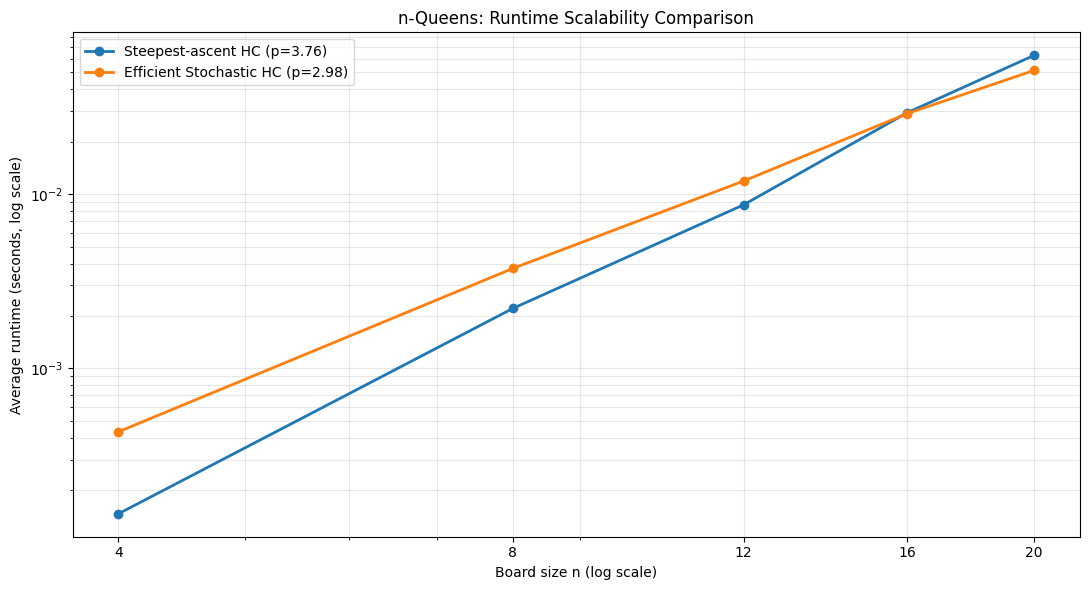

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.figure(figsize=(11, 6))

for name in algorithms:
    data = scale_df[scale_df["Algorithm"] == name]

    x = data["Board size (n)"].to_numpy(dtype=float)
    y = data["Avg. runtime (s)"].to_numpy(dtype=float)

    p = exponents[name]

    plt.plot(
        x, y,
        marker="o",
        linewidth=2,
        label=f"{name} (p={p:.2f})"
    )

plt.xscale("log")
plt.yscale("log")

plt.xticks(sizes, [str(n) for n in sizes])
plt.gca().xaxis.set_minor_formatter(ticker.NullFormatter())

plt.xlabel("Board size n (log scale)")
plt.ylabel("Average runtime (seconds, log scale)")
plt.title("n-Queens: Runtime Scalability Comparison")

plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

### Nhận xét 
Kết quả thực nghiệm cho thấy thời gian chạy của cả hai thuật toán đều tăng khi kích thước bàn cờ tăng từ n = 4 đến n = 20.

**Về thời gian thực thi:** Ở các kích thước nhỏ (n = 4, 8, 12), Steepest-ascent HC có thời gian chạy thấp hơn Efficient Stochastic HC. Tuy nhiên, khi n = 16, thời gian thực thi của hai thuật toán gần tương đương nhau. Đến n = 20, Efficient Stochastic HC có thời gian chạy thấp hơn, đạt 0,051395 giây so với 0,062710 giây của Steepest-ascent HC.

**Về khả năng mở rộng:** Biểu đồ log-log cho thấy thời gian chạy của Steepest-ascent HC có xu hướng tăng nhanh hơn Efficient Stochastic HC. Với số mũ thực nghiệm lần lượt là 3,76 và 2,98, Efficient Stochastic HC thể hiện khả năng mở rộng tốt hơn trong phạm vi khảo sát.

**Về chi phí đánh giá và chất lượng nghiệm:** Khi kích thước bàn cờ tăng, số lần đánh giá hàm mục tiêu và số xung đột cuối trung bình của cả hai thuật toán nhìn chung đều tăng. Tại n = 20, Steepest-ascent HC cần trung bình 3.478 lần đánh giá, cao hơn Efficient Stochastic HC với 2.304,15 lần. Tuy nhiên, số xung đột cuối của hai thuật toán khá tương đồng, lần lượt là 2,60 và 2,65.

**Kết luận:** Steepest-ascent HC có lợi thế về tốc độ ở các kích thước nhỏ, trong khi Efficient Stochastic HC có xu hướng mở rộng tốt hơn khi kích thước bài toán tăng. Tuy nhiên, kết quả còn phụ thuộc vào cách cài đặt, trạng thái khởi tạo và môi trường thực thi.